# ![PayLink Finance Made Simple Logo.png](PayLink%20Finance%20Made%20Simple%20Logo.png) Smarter Lending: Developing a Cost-Sensitive Loan Approval Model for FinTech Innovation
*CRISP-DM project · Risk Analytics team · Supervised classification on 20,000 historical loan applications*

## Overview
**Bottom line up front.** **Bottom line:** I have developed and fine-tuned a Logistic Regression model that uses only information available at the time of application to predict whether a loan applicant is likely to repay. The model performed very well, achieving a test ROC-AUC of
 0.989 and a PR-AUC of 0.968.

Since approving an applicant who defaults would cost $50,000, compared with $8,000 for denying a creditworthy applicant, I adjusted the decision threshold instead of using the standard 0.5 cut-off. Using a threshold of 0.93, selected through out-of-fold training predictions, the model achieved **96.5% precision among approved applicants**, well above the break-even requirement of 86.2%. At the same time, it approved **74% of creditworthy applicants**, helping balance the risk of costly defaults with the need to provide loans to deserving customers.

**What it is Matters.** When tested on 4,000 applications the model reduced the total cost of incorrect lending decisions to $3.26 million, or $815 per application. This is 57% lower than the $7.65 million cost of denying every applicant, saving approximately $21.9 million for every 20,000 applications processed. By comparison, approving everyone would result in costs of $152 million.

I also tested a Gradient Boosting model, which performed slightly better, with an AUC of 0.993 and a lower cost of $595 per application. However, it is more complex and may be harder to explain to regulators. The analysis estimates that choosing this model over Logistic Regression could save an additional $4.4 million per 20,000 applications. This gives management a clear basis for weighing the potential cost savings against the need for transparency and explainability in credit decisions.
 
1. **Data quality matters more than choosing a complex algorithm.** We found several data issues that could affect the model's reliability. For example, `RiskScore` is calculated after the lending decision, so including it would have produced misleadingly high performance. We therefore excluded it. We also found that about 1% of `AnnualIncome` values were inflated. In addition, all 901 applicants with missing `EducationLevel` values were denied loans, resulting in a 0% approval rate for this group. These findings highlight the importance of checking data quality and potential bias before building a model.

2. **Affordability is the main driver of credit decisions.** The model relies heavily on factors such as debt-to-income ratio, annual income, interest rate, credit score, and bankruptcy history. This makes practical sense because these factors help assess an applicant's ability to repay a loan. They also make the model's decisions easier to understand and explain.

3. **Fairness must be considered throughout the modelling process.** Removing Age, Marital Status, and Experience from the model had almost no impact on performance, with the AUC decreasing only slightly from 0.989 to 0.988. This suggests that we can exclude these characteristics while maintaining strong predictive performance. We therefore recommend excluding them from the production model while continuing to monitor approval rates and outcomes across different applicant groups to identify potential unfairness.



## 1. Business Understanding

### 1.1 The current process and its limits
FinTech Innovations partners with traditional banks to modernise loan approvals. Today the decision relies heavily on **manual review by loan officers**, which causes:

- **Inconsistent decisions**: two officers can reach different outcomes for near-identical applicants, which is a fairness and regulatory exposure.
- **Slow response times**: applicants wait, and good borrowers go to a competitor.
- **Hidden bias and missed opportunity**: traditional criteria can overlook creditworthy applicants.

### 1.2 Stakeholders and what each needs
| Stakeholder | What they need | How the model must serve them |
|---|---|---|
| **Loan officers** | Faster triage, a defensible second opinion, clear reasons for each decision | Probability output plus transparent drivers; a "review band" for borderline cases |
| **Management / Risk** | Lower default losses, higher throughput, a measurable ROI | Dollar-denominated performance metric tied to the $50k / $8k economics |
| **Customers (applicants)** | Fast, consistent, fair decisions and an explanation if denied | Interpretable model, no use of protected attributes where avoidable, bias audit |
| **Regulators / Compliance** | Explainability (adverse-action reasons), non-discrimination, auditability | Interpretable model family, segment fairness checks, documented pipeline |
| **Partner banks** | Portfolio quality | Control of the false-approval rate |

### 1.3 Why the two error types are not equal
Treat **"Approve" (1)** as the positive class.

| | Predict Deny | Predict Approve |
|---|---|---|
| **Actually Deny (should not be approved)** | ✔ $0 | ❌ **False Positive: approve a bad loan → –$50,000** (principal + collection costs) |
| **Actually Approve (creditworthy)** | ❌ **False Negative: deny a good loan → –$8,000** (lost profit) | ✔ $0 |

A false approval costs **6.25×** a false denial. This asymmetry drives every modelling decision below. It also means plain accuracy is the wrong yardstick, because a model can be 85% "accurate" and still lose tens of millions of dollars.

> **Important assumption (documented limitation).** The dataset contains the historical decision `LoanApproved`, not a realised-default flag. We therefore treat `LoanApproved` as the "ground truth" of creditworthiness and price its errors with the business costs above. In production the label should be replaced or augmented with actual repayment outcomes (see Conclusion).

### 1.4 Classification vs. regression
Two framings were offered: a **regression** risk score (`RiskScore`) or a **classification** of `LoanApproved`.

- **Classification is chosen as the primary approach.** The business outcome is a binary action (approve/deny) with a *known, asymmetric* payoff, so we can model the probability of approval and convert it to a decision with a **cost-optimal threshold**.
- **A calibrated probability gives us the best of both worlds**: it is a continuous risk score for loan officers *and* an automatable decision.
- **Regression is kept as a comparison** (Section 5.4): we predict `RiskScore` and convert it to a decision using a cutoff, to test whether the extra step helps or hurts. `RiskScore` itself is **not** used as a *feature* (see the leakage finding in Section 2).

### 1.5 Evaluation metrics and success criteria
| Metric | Why we use it |
|---|---|
| **Expected business cost ($ / application)**, our *custom metric* | `FP × $50,000 + FN × $8,000`. Directly equals the P&L impact; this is the metric the business cares about |
| **ROC-AUC** | Threshold-free ranking quality; lets us compare models before choosing a threshold |
| **PR-AUC (Average Precision)** | Robust to class imbalance (only ~24% approvals); focuses on the quality of approvals |
| **Precision of approvals** | If we approve, how often is it truly a good loan? Must exceed the break-even level below |
| **Recall of approvals** | How many creditworthy applicants do we capture (customer growth) |
| **F1** | Reported for completeness (symmetric, so *not* used to select the model) |

**Break-even logic.** Approving an applicant with approval-probability *p* has an expected cost of `(1–p)·$50,000`; denying costs `p·$8,000`. Approving is cheaper when **p > 50 / 58 = 0.862**. Equivalently, a policy of approving only beats "deny everyone" if its **precision exceeds 86.2%**. This is plotted below.

**Success criteria (set before modelling):**
1. ROC-AUC ≥ 0.90 on held-out data
2. Precision of approvals ≥ 90% (comfortably above the 86.2% break-even)
3. Total cost at least 50% below the best naive policy (deny-all)
4. Model remains interpretable (can generate adverse-action reasons) and shows no large fairness gaps across segments

In [1]:
# ---------------------------------------------------------------- Imports
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin, clone
from sklearn.utils.validation import validate_data
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, VotingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             confusion_matrix, roc_curve, precision_recall_curve, r2_score, mean_absolute_error)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Tuning budget (kept small so the notebook runs in a reasonable time; scale up for production)
N_ITER_LR, N_ITER_HGB, N_TREES = 20, 10, 200

ModuleNotFoundError: No module named 'numpy'

In [ ]:
# ---------------------------------------------------------------- Load data
DATA_PATH = "financial_loan_data.csv"          # place the CSV next to the notebook (or upload it in Colab)
df = pd.read_csv(DATA_PATH)

# AnnualIncome is stored as text like "$39,948.00" -> convert to float.
# This is a deterministic type fix (it learns nothing from the data), so doing it before the split is leakage-free.
df["AnnualIncome"] = df["AnnualIncome"].str.replace(r"[$,]", "", regex=True).astype(float)

TARGET = "LoanApproved"
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
df.head(3).T.head(12)

Rows: 20,000 | Columns: 35


,0,1,2
Age,45,38,47
AnnualIncome,39948.0,39709.0,40724.0
CreditScore,617,628,570
EmploymentStatus,Employed,Employed,Employed
EducationLevel,Master,Associate,Bachelor
Experience,22,15,26
LoanAmount,13152,26045,17627
LoanDuration,48,48,36
MaritalStatus,Married,Single,NaN
NumberOfDependents,2,1,2


Break-even approval probability = 0.862
A false approval costs 6.25x a false denial



,Total cost ($),Cost per application ($)
Deny everyone,"$38,240,000","$1,912"
Coin flip (50/50),"$399,620,000","$19,981"
Approve everyone,"$761,000,000","$38,050"
Perfect model (oracle),$0,$0


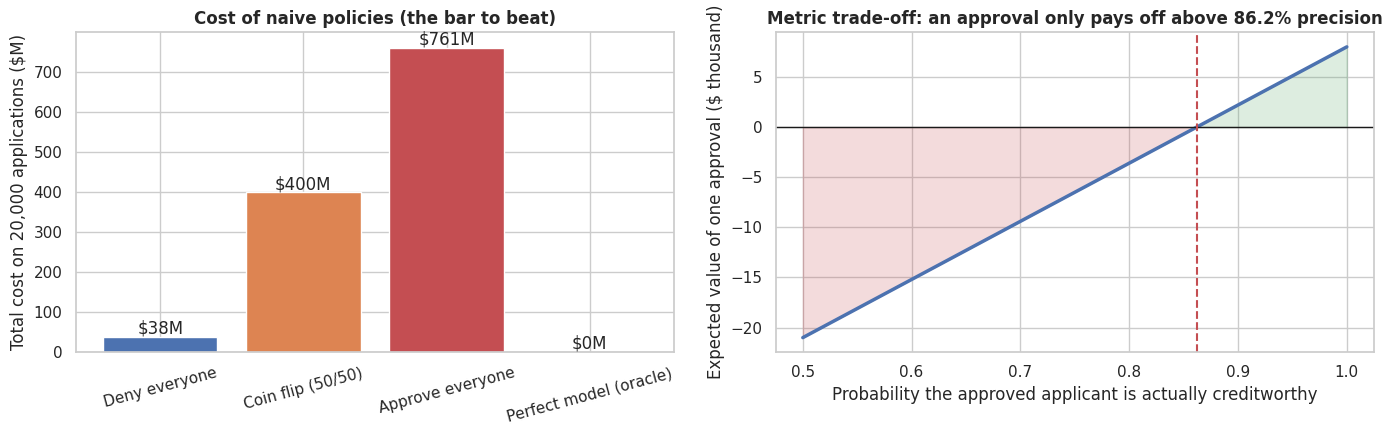

In [ ]:
# ---------------------------------------------------------------- Business cost model
FP_COST = 50_000    # approve a loan that should have been denied (default loss)
FN_COST = 8_000     # deny a creditworthy applicant (lost profit)
BREAKEVEN_P = FP_COST / (FP_COST + FN_COST)      # approve only if P(approve) > this

def business_cost(y_true, y_pred):
    """Custom metric: total dollar cost of errors. Positive class (1) = approve."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return fp * FP_COST + fn * FN_COST

def cost_scorer(estimator, X, y):
    """sklearn-compatible scorer: negative cost per application at the break-even threshold (higher = better)."""
    p = estimator.predict_proba(X)[:, 1]
    return -business_cost(y, (p >= BREAKEVEN_P).astype(int)) / len(y)

print(f"Break-even approval probability = {BREAKEVEN_P:.3f}")
print(f"A false approval costs {FP_COST/FN_COST:.2f}x a false denial\n")

# Naive policies on the full historical data
y_all = df[TARGET].values
n = len(y_all)
naive = pd.Series({
    "Deny everyone":            business_cost(y_all, np.zeros(n, int)),
    "Coin flip (50/50)":        0.5 * (y_all == 0).sum() * FP_COST + 0.5 * (y_all == 1).sum() * FN_COST,
    "Approve everyone":         business_cost(y_all, np.ones(n, int)),
    "Perfect model (oracle)":   0,
})
naive_df = pd.DataFrame({"Total cost ($)": naive, "Cost per application ($)": naive / n})
display(naive_df.style.format("${:,.0f}"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["#4c72b0", "#dd8452", "#c44e52", "#55a868"]
ax[0].bar(naive.index, naive.values / 1e6, color=colors)
ax[0].set_ylabel("Total cost on 20,000 applications ($M)")
ax[0].set_title("Cost of naive policies (the bar to beat)")
for i, v in enumerate(naive.values / 1e6): ax[0].text(i, v + 8, f"${v:,.0f}M", ha="center")
ax[0].tick_params(axis="x", rotation=15)

prec = np.linspace(0.5, 1, 200)
gain = prec * FN_COST - (1 - prec) * FP_COST           # value of one approval relative to denying
ax[1].plot(prec, gain / 1000, lw=2.5, color="#4c72b0")
ax[1].axhline(0, color="k", lw=1); ax[1].axvline(BREAKEVEN_P, color="#c44e52", ls="--")
ax[1].fill_between(prec, gain / 1000, 0, where=gain > 0, alpha=.2, color="#55a868")
ax[1].fill_between(prec, gain / 1000, 0, where=gain < 0, alpha=.2, color="#c44e52")
ax[1].set_title(f"Metric trade-off: an approval only pays off above {BREAKEVEN_P:.1%} precision")
ax[1].set_xlabel("Probability the approved applicant is actually creditworthy")
ax[1].set_ylabel("Expected value of one approval ($ thousand)")
plt.tight_layout(); plt.show()

## 2. Data Understanding
The EDA follows a funnel: **(a)** basic characteristics and data quality → **(b)** feature typing and missingness → **(c)** target and class imbalance → **(d)** univariate distributions and outliers → **(e)** feature-vs-target relationships with statistical tests → **(f)** multivariate structure (correlations, pair plots) → **(g)** feature-engineering opportunities.

In [ ]:
# ---------------------------------------------------------------- (a) Basic characteristics
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print(f"Memory: {df.memory_usage(deep=True).sum()/1e6:.1f} MB\n")

cat_cols_all = ["EmploymentStatus", "EducationLevel", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "BankruptcyHistory"]
num_cols = [c for c in df.columns if c not in cat_cols_all + [TARGET, "RiskScore"]]

desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
display(desc[["count", "mean", "std", "min", "50%", "max", "skew"]].round(2))

Shape: (20000, 35)
Duplicate rows: 0
Memory: 11.3 MB



,count,mean,std,min,50%,max,skew
Age,20000.0,39.75,11.62,18.00,40.00,80.00,0.19
AnnualIncome,20000.0,59161.47,40350.85,15000.00,48566.00,485341.00,2.09
CreditScore,20000.0,571.61,51.00,343.00,578.00,712.00,-0.60
Experience,20000.0,17.52,11.32,0.00,17.00,61.00,0.34
LoanAmount,20000.0,24882.87,13427.42,3674.00,21914.50,184732.00,1.83
LoanDuration,20000.0,54.06,24.66,12.00,48.00,120.00,0.65
NumberOfDependents,20000.0,1.52,1.39,0.00,1.00,5.00,0.64
MonthlyDebtPayments,20000.0,454.29,240.51,50.00,402.00,2919.00,1.65
CreditCardUtilizationRate,20000.0,0.29,0.16,0.00,0.27,0.92,0.60
NumberOfOpenCreditLines,20000.0,3.02,1.74,0.00,3.00,13.00,0.60


,Group,Features
0,"Numeric (continuous, right-skewed $ amounts)","AnnualIncome, MonthlyIncome, LoanAmount, MonthlyDebtPayments, MonthlyLoanPayment, TotalAssets, TotalLiabilities, NetWorth, SavingsAccountBalance, CheckingAccountBalance"
1,Numeric (counts / scores / ratios),"Age, CreditScore, Experience, LoanDuration, NumberOfDependents, CreditCardUtilizationRate, NumberOfOpenCreditLines, NumberOfCreditInquiries, DebtToIncomeRatio, PaymentHistory, LengthOfCreditHistory, UtilityBillsPaymentHistory, JobTenure, BaseInterestRate, InterestRate, TotalDebtToIncomeRatio, PreviousLoanDefaults (0/1)"
2,Ordinal,EducationLevel (High School < Associate < Bachelor < Master < Doctorate)
3,Nominal categorical,"EmploymentStatus, MaritalStatus, HomeOwnershipStatus, LoanPurpose"
4,Binary categorical,BankruptcyHistory (Yes/No)
5,Target,LoanApproved (1 = approved)
6,Excluded (leakage),RiskScore (see Section 2c)


,missing,pct
EducationLevel,901,4.50
MaritalStatus,1331,6.66
SavingsAccountBalance,572,2.86


,feature,approval rate if present,approval rate if missing,chi2 p-value
0,EducationLevel,0.2503,0.0000,0.0000
1,MaritalStatus,0.2386,0.2449,0.6229
2,SavingsAccountBalance,0.2383,0.2640,0.1701


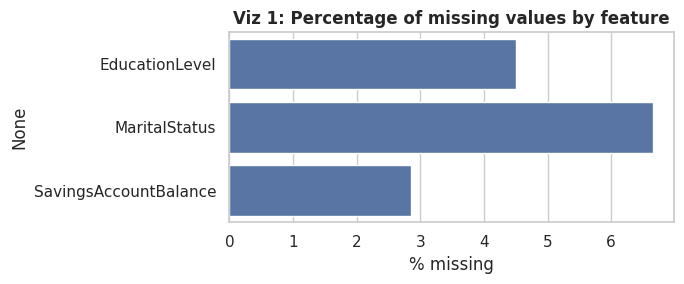

In [ ]:
# ---------------------------------------------------------------- (b) Feature typing & missing values
feature_types = pd.DataFrame({
    "Group": ["Numeric (continuous, right-skewed $ amounts)", "Numeric (counts / scores / ratios)",
              "Ordinal", "Nominal categorical", "Binary categorical", "Target", "Excluded (leakage)"],
    "Features": [
        "AnnualIncome, MonthlyIncome, LoanAmount, MonthlyDebtPayments, MonthlyLoanPayment, TotalAssets, TotalLiabilities, NetWorth, SavingsAccountBalance, CheckingAccountBalance",
        "Age, CreditScore, Experience, LoanDuration, NumberOfDependents, CreditCardUtilizationRate, NumberOfOpenCreditLines, NumberOfCreditInquiries, DebtToIncomeRatio, PaymentHistory, LengthOfCreditHistory, UtilityBillsPaymentHistory, JobTenure, BaseInterestRate, InterestRate, TotalDebtToIncomeRatio, PreviousLoanDefaults (0/1)",
        "EducationLevel (High School < Associate < Bachelor < Master < Doctorate)",
        "EmploymentStatus, MaritalStatus, HomeOwnershipStatus, LoanPurpose",
        "BankruptcyHistory (Yes/No)", "LoanApproved (1 = approved)", "RiskScore (see Section 2c)"]})
display(feature_types.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

miss = df.isna().sum().loc[lambda s: s > 0].to_frame("missing"); miss["pct"] = 100 * miss["missing"] / len(df)
display(miss.round(2))

# Is missingness informative? chi-square of "is missing" vs the target
rows = []
for c in miss.index:
    ct = pd.crosstab(df[c].isna(), df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "approval rate if present": df.loc[df[c].notna(), TARGET].mean(),
                 "approval rate if missing": df.loc[df[c].isna(), TARGET].mean(), "chi2 p-value": p})
display(pd.DataFrame(rows).round(4))

fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(x=miss["pct"], y=miss.index, ax=ax, color="#4c72b0")
ax.set_title("Viz 1: Percentage of missing values by feature"); ax.set_xlabel("% missing")
plt.tight_layout(); plt.show()

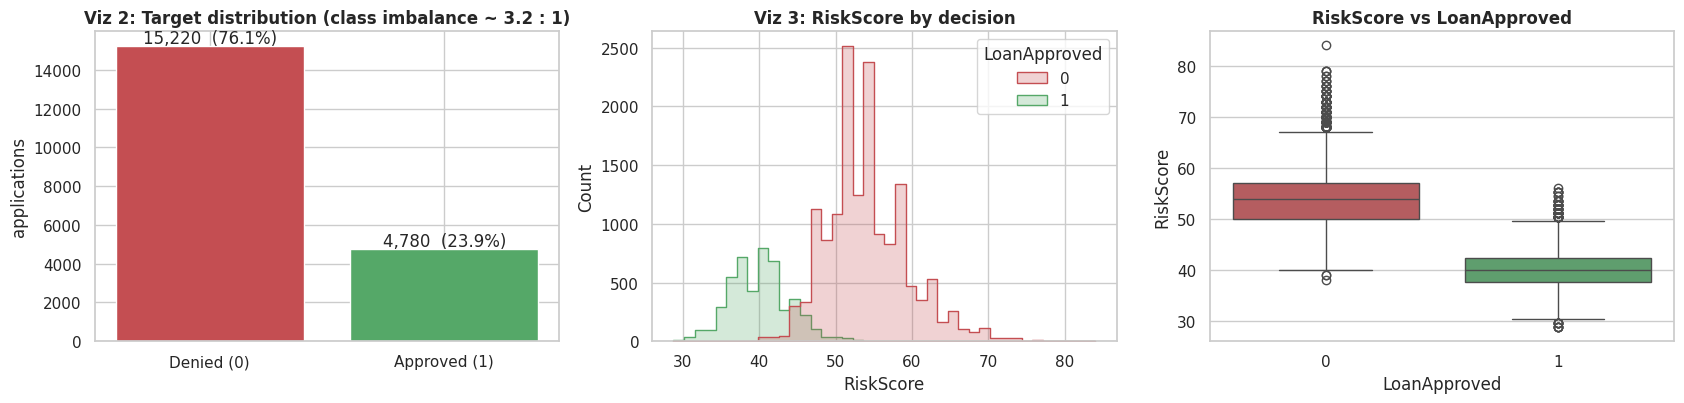

Imbalance ratio (denied : approved) = 3.18 : 1
Single-feature ROC-AUC of RiskScore alone for LoanApproved: 0.987
Mean RiskScore | approved = 40.1, denied = 54.1  (ratio 0.74)
Max RiskScore among approved: 56.0 | Min among denied: 38.0


In [ ]:
# ---------------------------------------------------------------- (c) Target, class imbalance and the RiskScore leakage check
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
vc = df[TARGET].value_counts().sort_index()
ax[0].bar(["Denied (0)", "Approved (1)"], vc.values, color=["#c44e52", "#55a868"])
for i, v in enumerate(vc.values): ax[0].text(i, v + 150, f"{v:,}  ({v/len(df):.1%})", ha="center")
ax[0].set_title("Viz 2: Target distribution (class imbalance ~ 3.2 : 1)"); ax[0].set_ylabel("applications")

sns.histplot(data=df, x="RiskScore", hue=TARGET, bins=40, ax=ax[1], palette=["#c44e52", "#55a868"], element="step")
ax[1].set_title("Viz 3: RiskScore by decision")

sns.boxplot(data=df, x=TARGET, y="RiskScore", ax=ax[2], palette=["#c44e52", "#55a868"])
ax[2].set_title("RiskScore vs LoanApproved"); plt.tight_layout(); plt.show()

print(f"Imbalance ratio (denied : approved) = {vc[0]/vc[1]:.2f} : 1")
print(f"Single-feature ROC-AUC of RiskScore alone for LoanApproved: {roc_auc_score(df[TARGET], -df['RiskScore']):.3f}")
print(f"Mean RiskScore | approved = {df.loc[df[TARGET]==1,'RiskScore'].mean():.1f}, denied = {df.loc[df[TARGET]==0,'RiskScore'].mean():.1f}  "
      f"(ratio {df.loc[df[TARGET]==1,'RiskScore'].mean()/df.loc[df[TARGET]==0,'RiskScore'].mean():.2f})")
print("Max RiskScore among approved:", df.loc[df[TARGET]==1,'RiskScore'].max(), "| Min among denied:", df.loc[df[TARGET]==0,'RiskScore'].min())

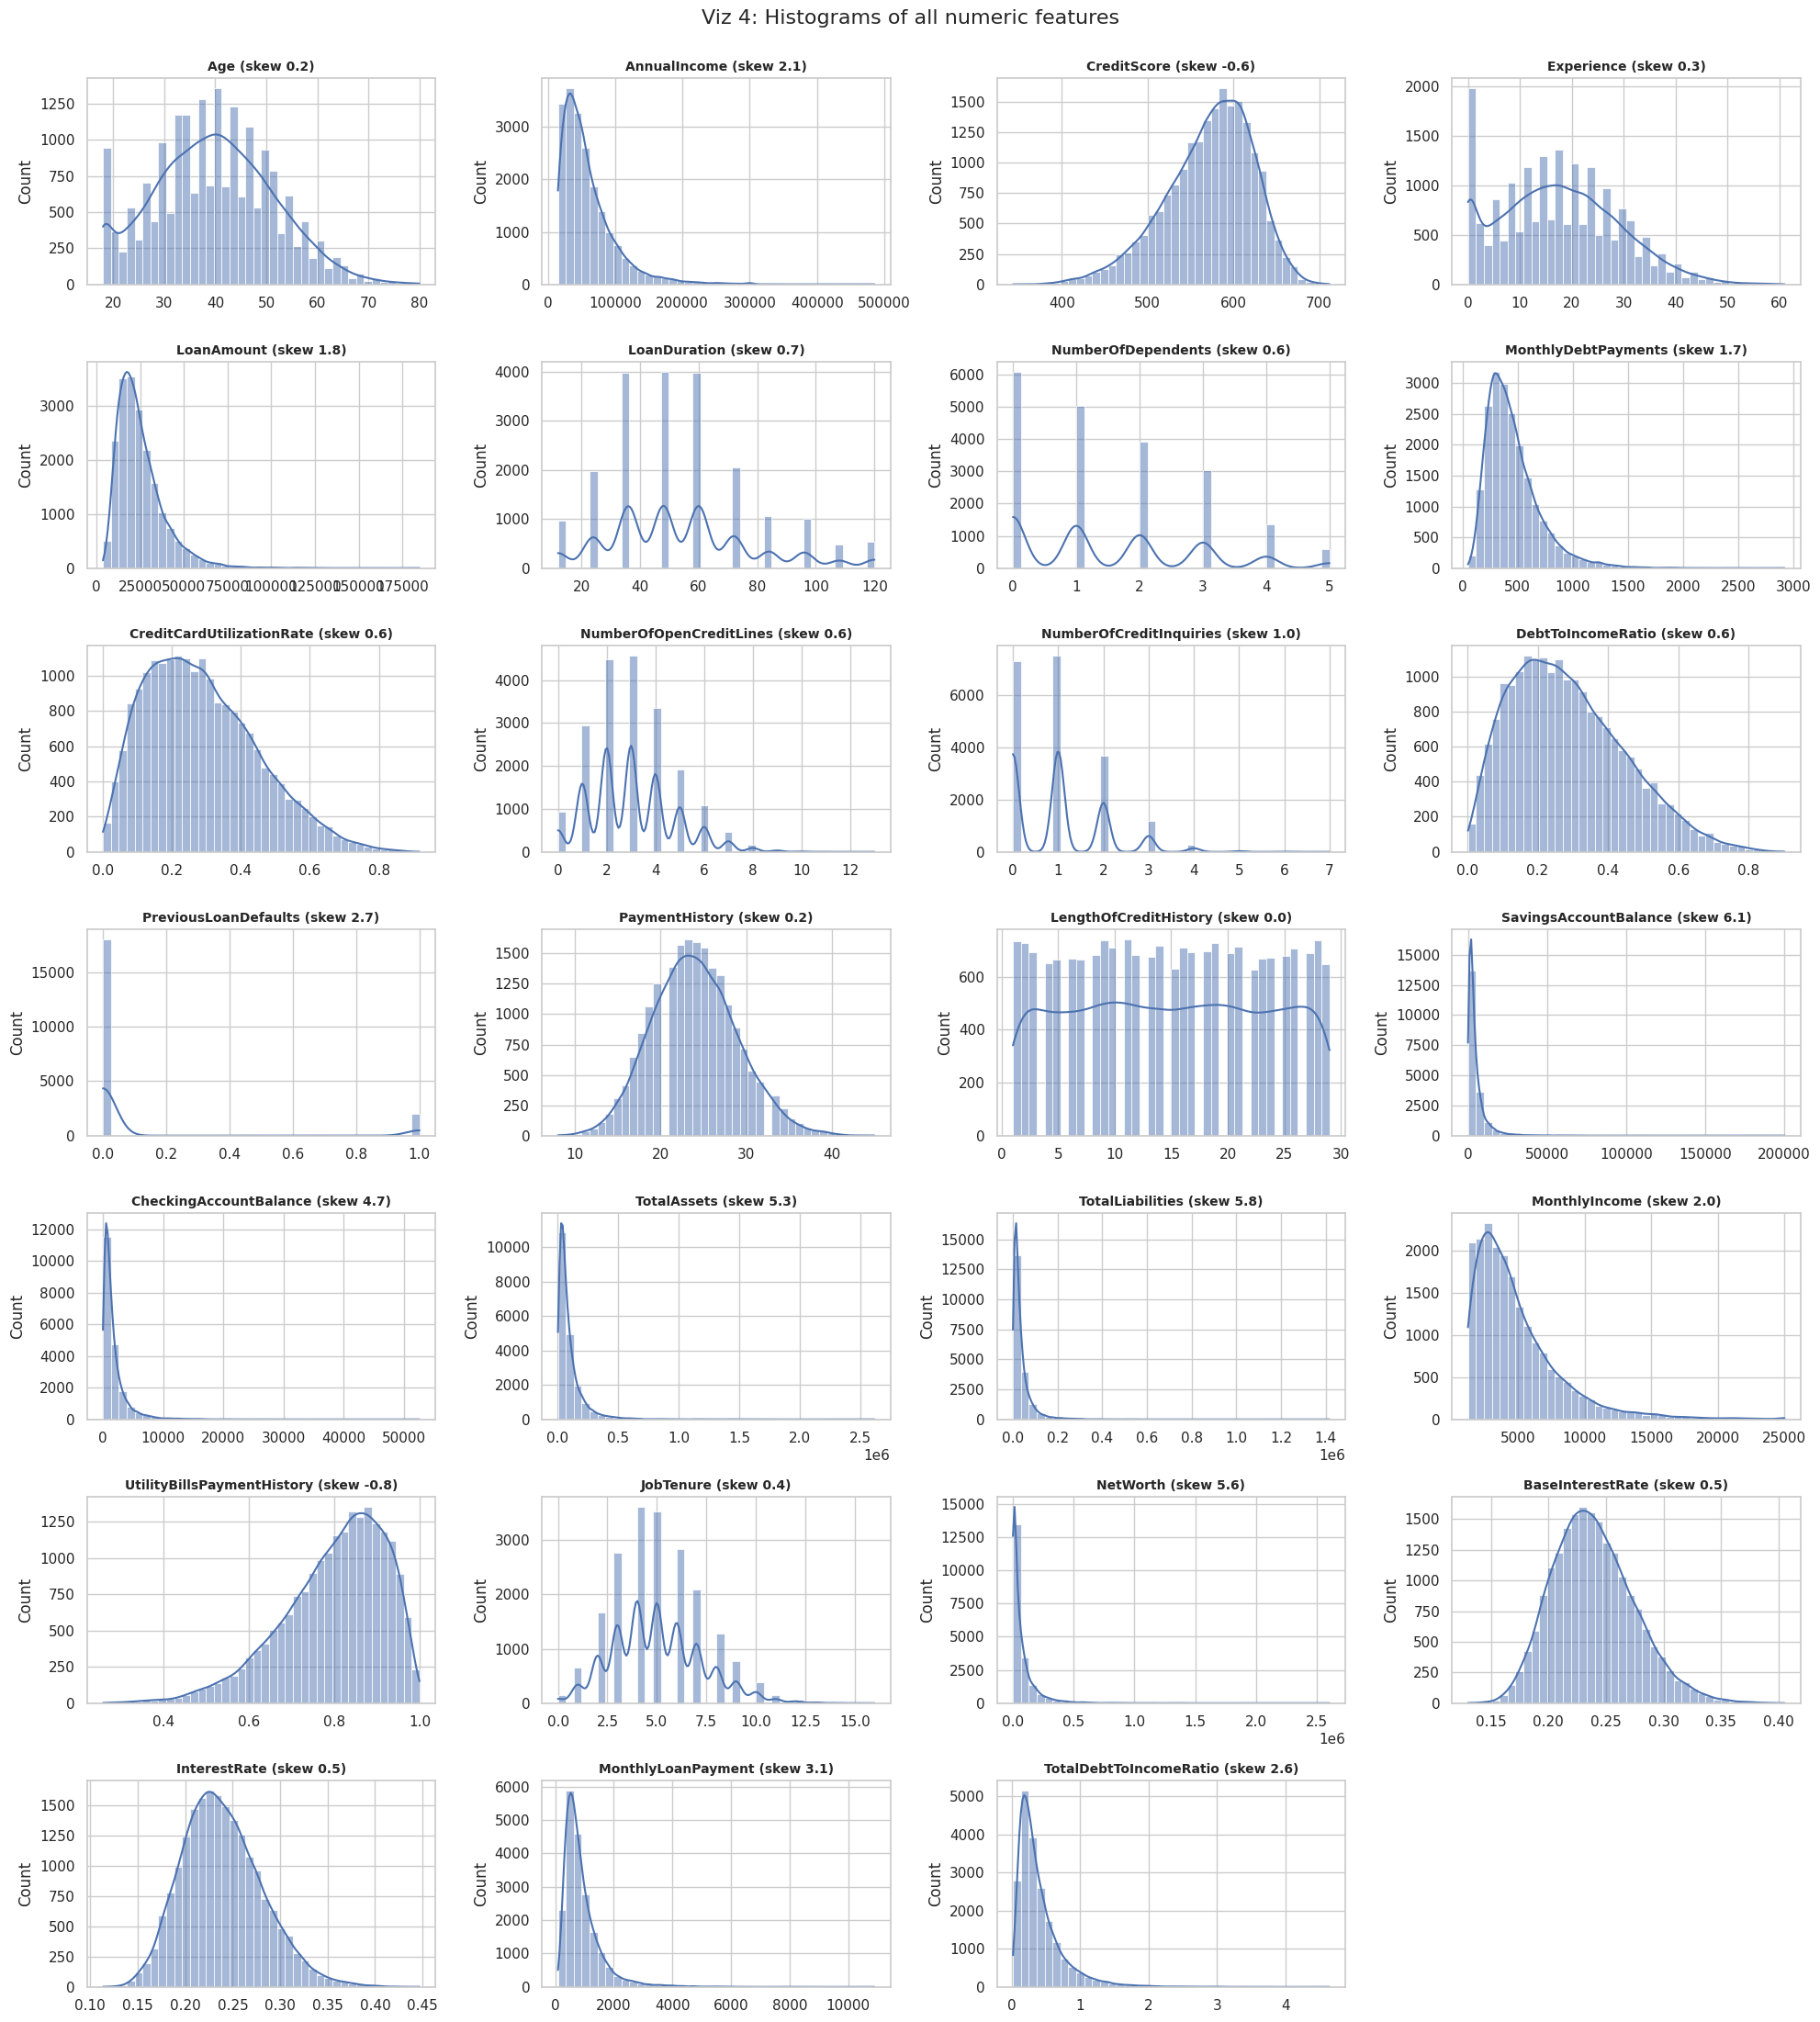

,skew before,skew after log1p
AnnualIncome,2.09,0.16
LoanAmount,1.83,0.02
MonthlyDebtPayments,1.65,-0.02
PreviousLoanDefaults,2.67,2.67
SavingsAccountBalance,6.10,-0.01
CheckingAccountBalance,4.75,-0.04
TotalAssets,5.31,0.04
TotalLiabilities,5.85,-0.01
MonthlyIncome,1.99,0.15
NetWorth,5.60,-0.09


In [ ]:
# ---------------------------------------------------------------- (d) Univariate distributions
fig, axes = plt.subplots(7, 4, figsize=(20, 22))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, color="#4c72b0", kde=True)
    ax.set_title(f"{c} (skew {df[c].skew():.1f})", fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]: ax.axis("off")
fig.suptitle("Viz 4: Histograms of all numeric features", fontsize=16, y=1.0)
plt.tight_layout(); plt.show()

# Does a log transform fix the skew? (motivates the preprocessing design)
skewed = [c for c in num_cols if df[c].skew() > 1.5 and df[c].min() >= 0]
sk = pd.DataFrame({"skew before": df[skewed].skew(), "skew after log1p": np.log1p(df[skewed]).skew()})
display(sk.round(2))

,% outside 1.5*IQR
PreviousLoanDefaults,10.01
SavingsAccountBalance,7.96
NetWorth,7.82
TotalLiabilities,7.66
CheckingAccountBalance,7.61
TotalAssets,7.21
TotalDebtToIncomeRatio,5.76
MonthlyLoanPayment,5.44
AnnualIncome,4.74
MonthlyIncome,4.62



Rows where AnnualIncome != 12*MonthlyIncome: 195 (0.97%); ratio in those rows ranges 1.50 - 2.00


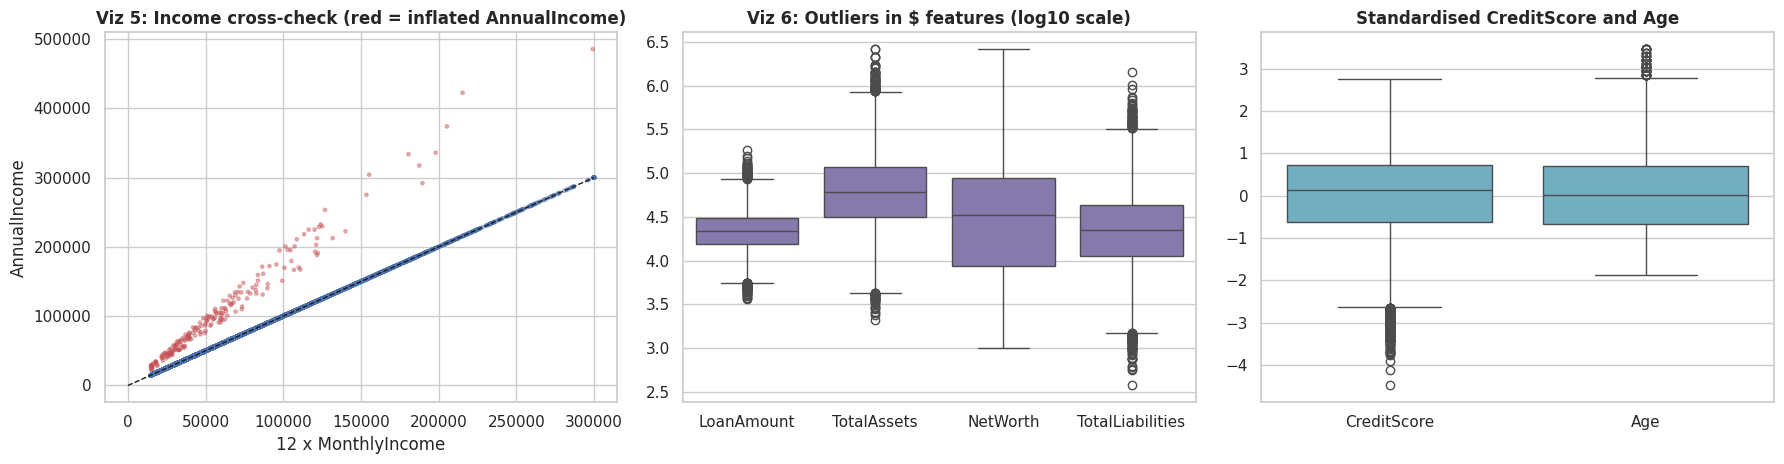

In [ ]:
# ---------------------------------------------------------------- (d) Outliers
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100
out = pd.Series({c: iqr_outliers(df[c].dropna()) for c in num_cols}).sort_values(ascending=False)
display(out.head(10).round(2).to_frame("% outside 1.5*IQR"))

# Income consistency: AnnualIncome vs MonthlyIncome*12 should be identical
ratio = df["AnnualIncome"] / (12 * df["MonthlyIncome"])
mismatch = (ratio - 1).abs() > 0.05
print(f"\nRows where AnnualIncome != 12*MonthlyIncome: {mismatch.sum()} ({mismatch.mean():.2%}); "
      f"ratio in those rows ranges {ratio[mismatch].min():.2f} - {ratio[mismatch].max():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(12 * df["MonthlyIncome"], df["AnnualIncome"], s=6, alpha=.4, c=np.where(mismatch, "#c44e52", "#4c72b0"))
ax[0].plot([0, 3e5], [0, 3e5], "k--", lw=1); ax[0].set_xlabel("12 x MonthlyIncome"); ax[0].set_ylabel("AnnualIncome")
ax[0].set_title("Viz 5: Income cross-check (red = inflated AnnualIncome)")
sns.boxplot(data=df[["LoanAmount", "TotalAssets", "NetWorth", "TotalLiabilities"]].apply(np.log10), ax=ax[1], color="#8172b3")
ax[1].set_title("Viz 6: Outliers in $ features (log10 scale)")
sns.boxplot(data=df[["CreditScore", "Age"]].apply(lambda s: (s - s.mean()) / s.std()), ax=ax[2], color="#64b5cd")
ax[2].set_title("Standardised CreditScore and Age"); plt.tight_layout(); plt.show()

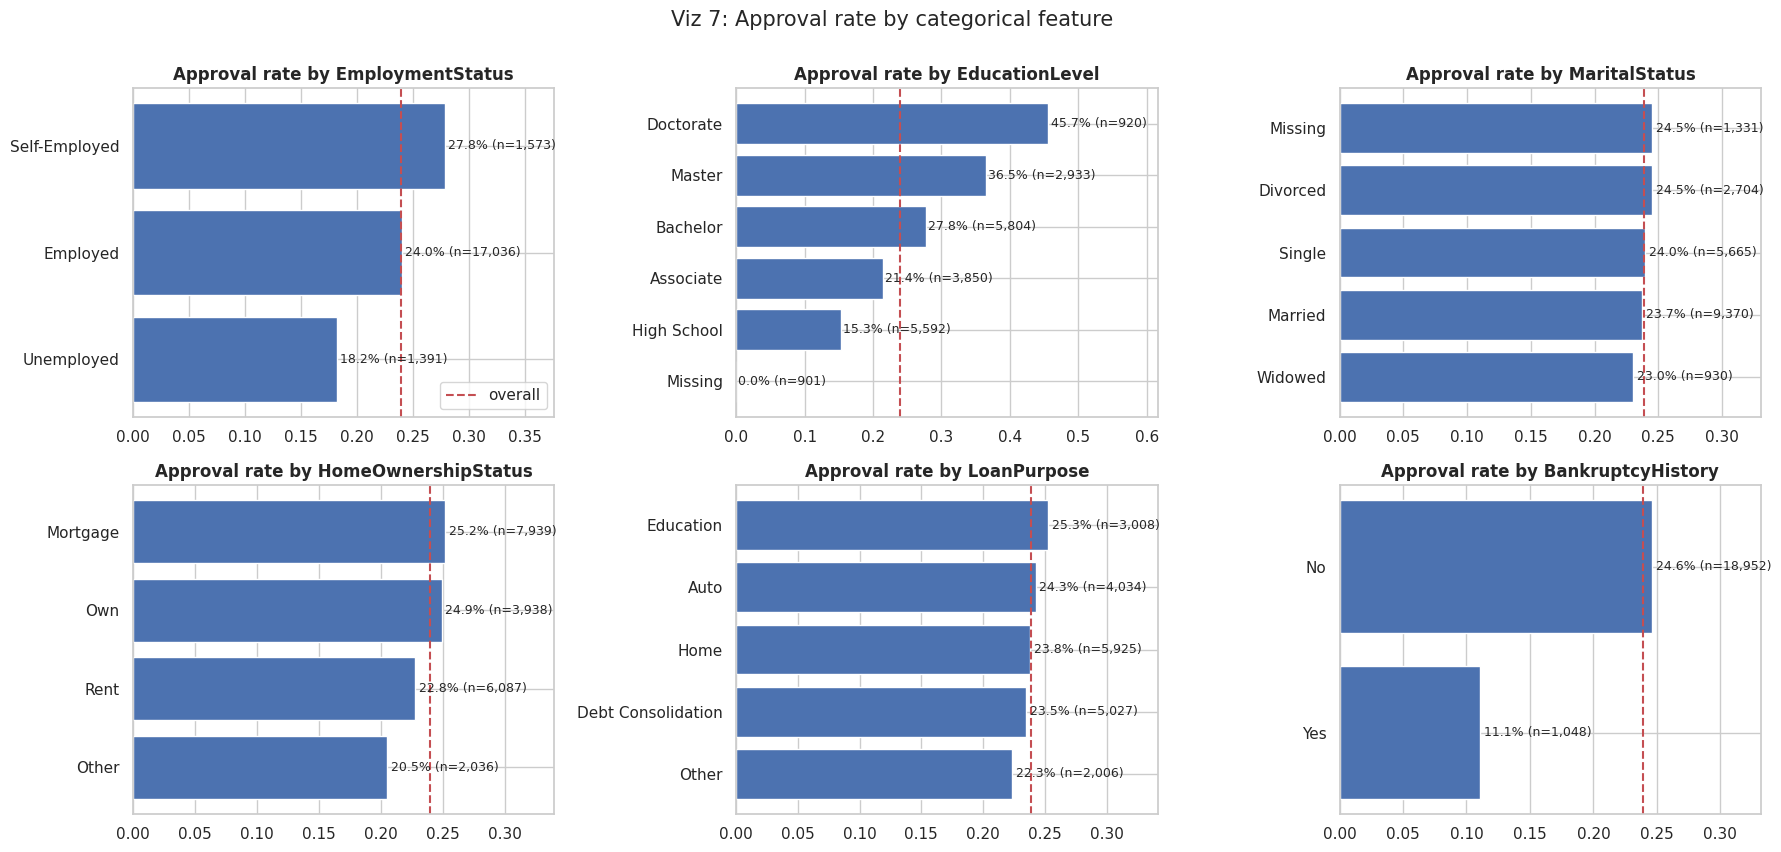

,chi2,dof,p-value,Cramer's V
feature,,,,
EducationLevel,1068.9276,5,0.0000,0.2312
BankruptcyHistory,99.3709,1,0.0000,0.0705
EmploymentStatus,38.5065,2,0.0000,0.0439
HomeOwnershipStatus,26.3288,3,0.0000,0.0363
LoanPurpose,6.6957,4,0.1529,0.0183
MaritalStatus,1.3740,4,0.8487,0.0083


In [ ]:
# ---------------------------------------------------------------- (e) Categorical features vs target
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
rows = []
for ax, c in zip(axes.ravel(), cat_cols_all):
    s = df[c].fillna("Missing")
    rate = df.groupby(s)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(rate.index.astype(str), rate["mean"], color="#4c72b0")
    ax.axvline(df[TARGET].mean(), color="#c44e52", ls="--", label="overall")
    for i, (m, k) in enumerate(zip(rate["mean"], rate["size"])): ax.text(m + .003, i, f"{m:.1%} (n={k:,})", va="center", fontsize=9)
    ax.set_title(f"Approval rate by {c}"); ax.set_xlim(0, rate["mean"].max() * 1.35)
    ct = pd.crosstab(s, df[TARGET]); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "chi2": chi2, "dof": dof, "p-value": p, "Cramer's V": cramers_v(ct)})
axes.ravel()[0].legend()
fig.suptitle("Viz 7: Approval rate by categorical feature", fontsize=15, y=1.0); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(4))

Share of numeric features passing D'Agostino normality test (n=5000 sample): 0%  -> use rank-based (Mann-Whitney U) rather than t-tests



,median approved,median denied,rank-biserial r,p-value,spearman vs target,|effect|
feature,,,,,,
TotalDebtToIncomeRatio,0.1376,0.3809,-0.8128,0.0,-0.6004,0.8128
MonthlyIncome,7572.2917,3365.6667,0.7700,0.0,0.5688,0.7700
AnnualIncome,91269.5000,40557.5000,0.7674,0.0,0.5669,0.7674
InterestRate,0.2136,0.2429,-0.4169,0.0,-0.3080,0.4169
LoanAmount,17336.5000,23566.0000,-0.3522,0.0,-0.2602,0.3522
BaseInterestRate,0.2209,0.2411,-0.3372,0.0,-0.2491,0.3372
MonthlyLoanPayment,576.0348,791.2212,-0.3008,0.0,-0.2222,0.3008
Experience,20.0000,16.0000,0.1957,0.0,0.1446,0.1957
Age,42.0000,39.0000,0.1941,0.0,0.1434,0.1941


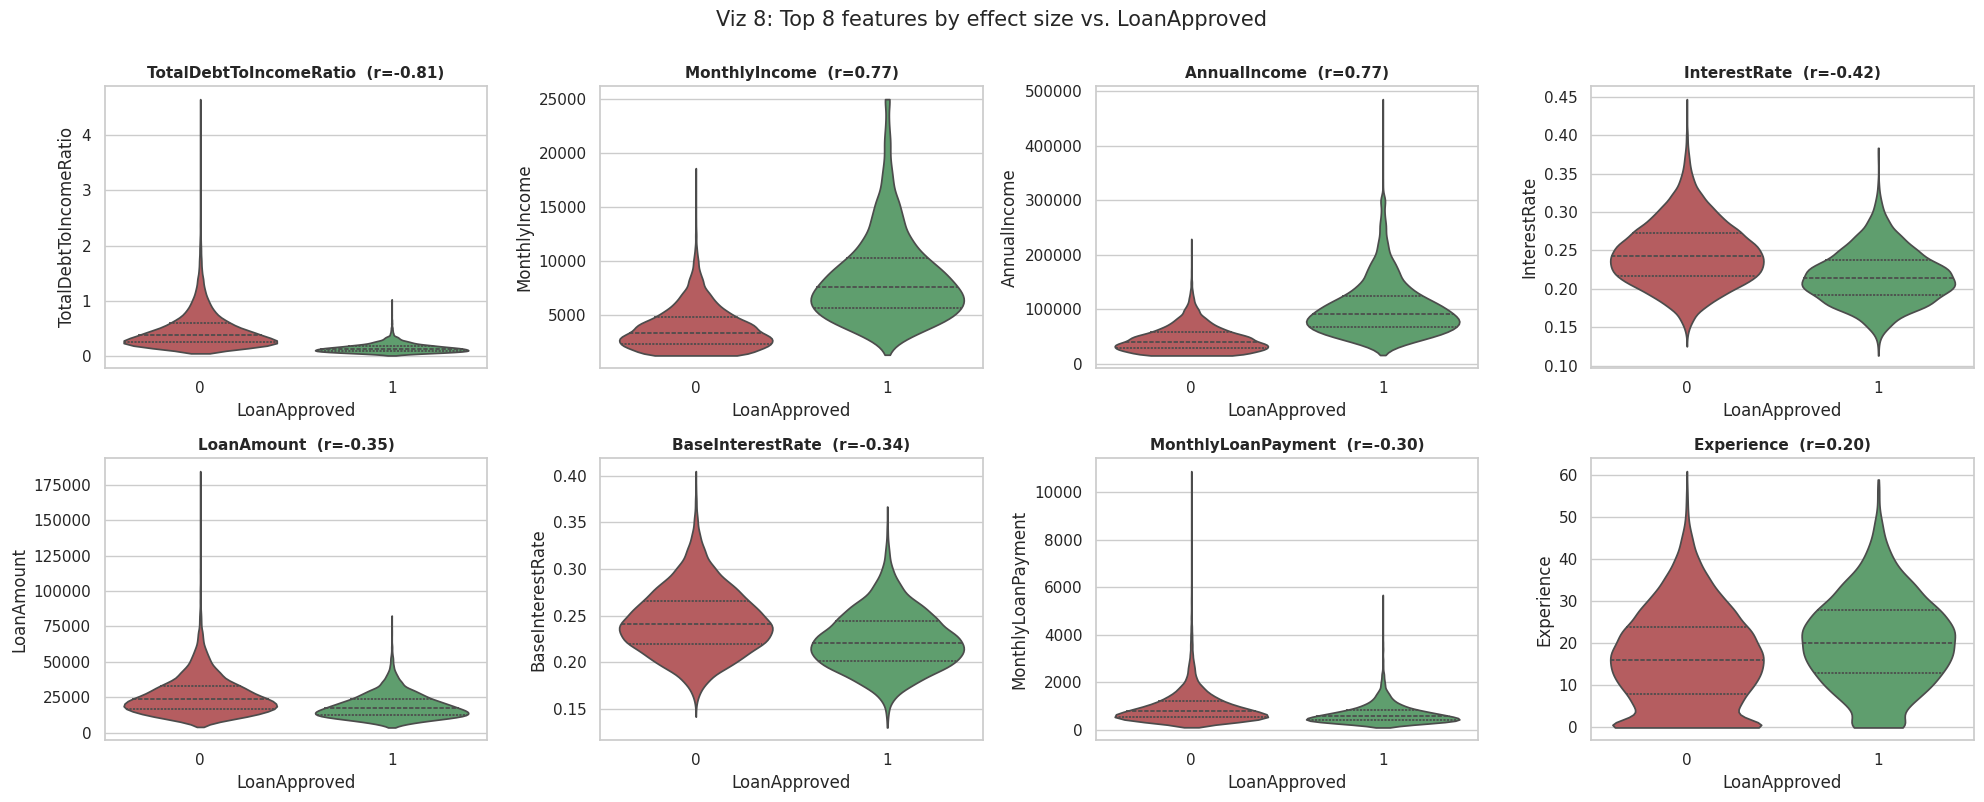

In [ ]:
# ---------------------------------------------------------------- (e) Numeric features vs target: normality + non-parametric tests
sample = df[num_cols].sample(5000, random_state=SEED)
normal_share = np.mean([stats.normaltest(sample[c].dropna())[1] > 0.05 for c in num_cols])
print(f"Share of numeric features passing D'Agostino normality test (n=5000 sample): {normal_share:.0%}"
      "  -> use rank-based (Mann-Whitney U) rather than t-tests\n")

rows = []
for c in num_cols:
    a, b = df.loc[df[TARGET] == 1, c].dropna(), df.loc[df[TARGET] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"feature": c, "median approved": a.median(), "median denied": b.median(),
                 "rank-biserial r": 2 * u / (len(a) * len(b)) - 1, "p-value": p,
                 "spearman vs target": stats.spearmanr(df[c], df[TARGET], nan_policy="omit")[0]})
tests = pd.DataFrame(rows).set_index("feature")
tests["|effect|"] = tests["rank-biserial r"].abs()
tests = tests.sort_values("|effect|", ascending=False)
display(tests.head(12).round(4))

top = tests.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), top):
    sns.violinplot(data=df, x=TARGET, y=c, ax=ax, palette=["#c44e52", "#55a868"], cut=0, inner="quartile")
    ax.set_title(f"{c}  (r={tests.loc[c,'rank-biserial r']:.2f})", fontsize=11); ax.set_xlabel("LoanApproved")
fig.suptitle("Viz 8: Top 8 features by effect size vs. LoanApproved", fontsize=15, y=1.0); plt.tight_layout(); plt.show()

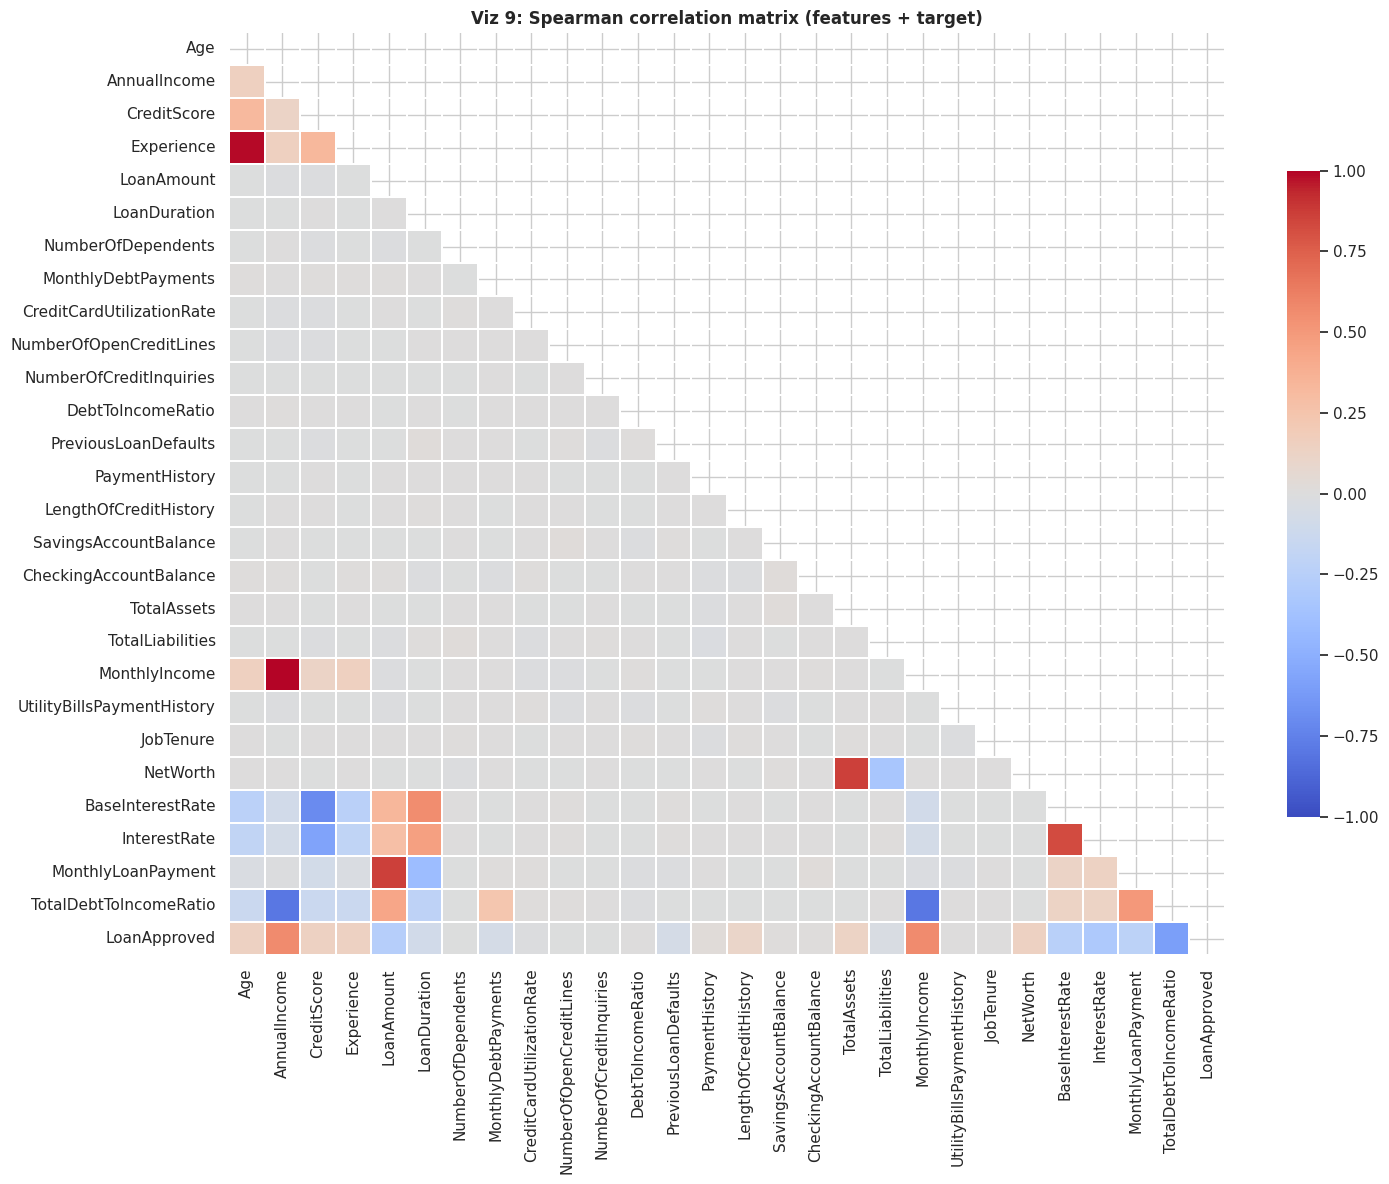

Highly collinear feature pairs (|rho| > 0.7):


,f1,f2,rho
533,MonthlyIncome,AnnualIncome,0.996
84,Experience,Age,0.985
704,MonthlyLoanPayment,LoanAmount,0.867
633,NetWorth,TotalAssets,0.860
695,InterestRate,BaseInterestRate,0.821
747,TotalDebtToIncomeRatio,MonthlyIncome,-0.803
729,TotalDebtToIncomeRatio,AnnualIncome,-0.800
646,BaseInterestRate,CreditScore,-0.703


In [ ]:
# ---------------------------------------------------------------- (f) Multivariate structure
corr = df[num_cols + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.3, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Viz 9: Spearman correlation matrix (features + target)"); plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack().reset_index(); pairs.columns = ["f1", "f2", "rho"]
pairs = pairs[(pairs.f1 != TARGET) & (pairs.f2 != TARGET) & (pairs.rho.abs() > 0.7)].sort_values("rho", key=abs, ascending=False)
print("Highly collinear feature pairs (|rho| > 0.7):"); display(pairs.round(3))

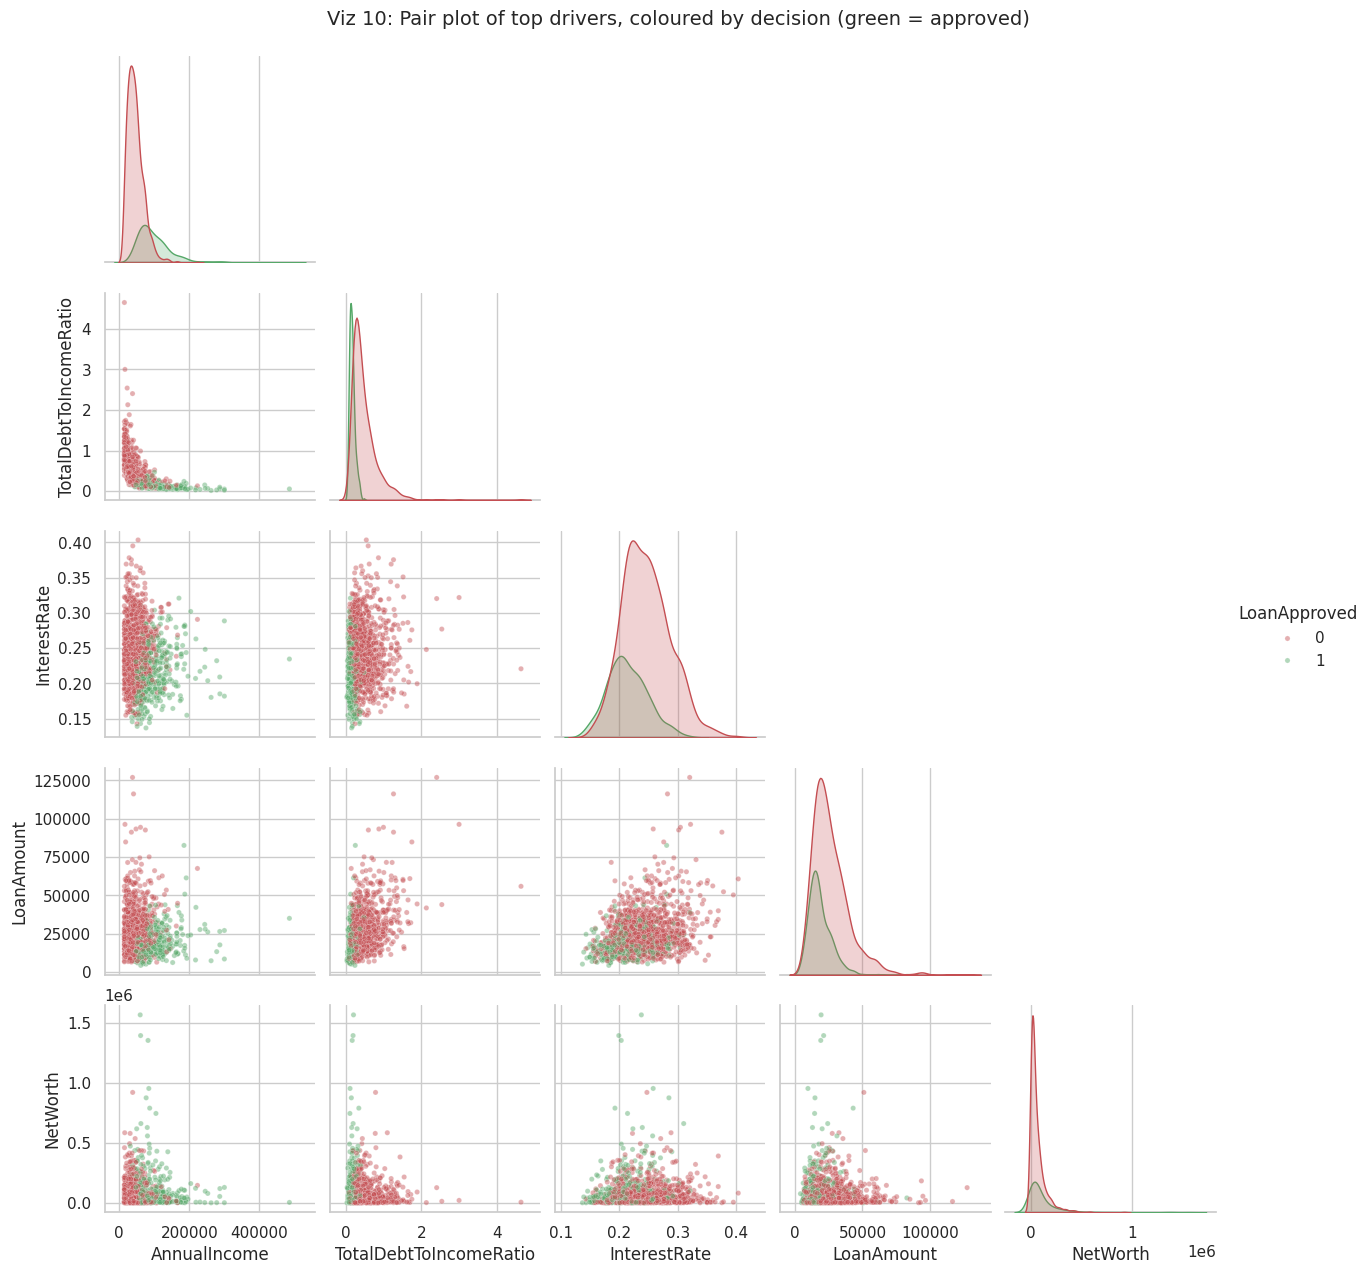

In [ ]:
# Pair plot of the strongest drivers (sampled for readability)
drivers = ["AnnualIncome", "TotalDebtToIncomeRatio", "InterestRate", "LoanAmount", "NetWorth"]
g = sns.pairplot(df.sample(1500, random_state=SEED)[drivers + [TARGET]], hue=TARGET, corner=True,
                 palette=["#c44e52", "#55a868"], plot_kws={"alpha": .45, "s": 14}, diag_kind="kde")
g.fig.suptitle("Viz 10: Pair plot of top drivers, coloured by decision (green = approved)", y=1.02, fontsize=14)
plt.show()

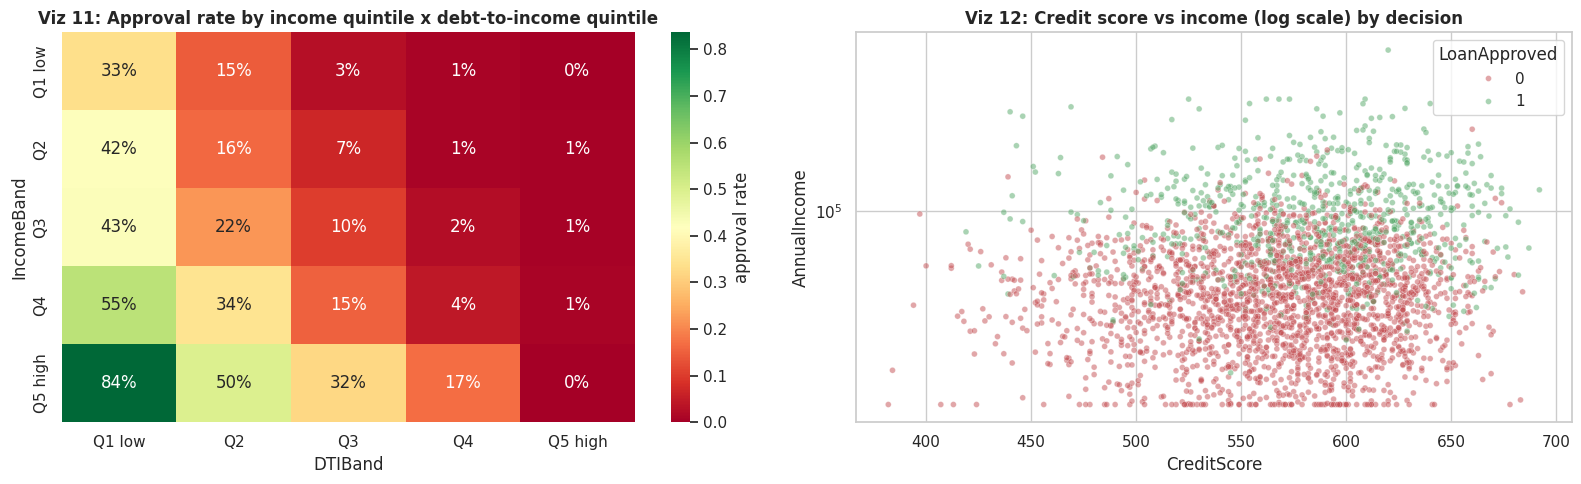

In [ ]:
# Multivariate look at the two things a regulator will ask about: affordability and age/credit profile
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
tmp = df.assign(IncomeBand=pd.qcut(df["AnnualIncome"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]),
                DTIBand=pd.qcut(df["TotalDebtToIncomeRatio"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]))
sns.heatmap(tmp.pivot_table(index="IncomeBand", columns="DTIBand", values=TARGET, aggfunc="mean", observed=True),
            annot=True, fmt=".0%", cmap="RdYlGn", ax=ax[0], cbar_kws={"label": "approval rate"})
ax[0].set_title("Viz 11: Approval rate by income quintile x debt-to-income quintile")
sns.scatterplot(data=df.sample(3000, random_state=SEED), x="CreditScore", y="AnnualIncome", hue=TARGET,
                palette=["#c44e52", "#55a868"], alpha=.5, s=18, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_title("Viz 12: Credit score vs income (log scale) by decision")
plt.tight_layout(); plt.show()

### 2.x Feature understanding and data-quality log
**Data characteristics and quality**
- 20,000 rows, 33 predictors after setting aside the target and `RiskScore`; no duplicate rows. `AnnualIncome` was stored as text (`"$39,948.00"`) and was converted to a number.
- **Class imbalance:** 76.1% denied vs 23.9% approved (3.18 : 1). Handled with stratified splits, imbalance-robust metrics (PR-AUC) and cost-based thresholding.
- **Missing values (3 features):** `EducationLevel` 4.5%, `MaritalStatus` 6.7%, `SavingsAccountBalance` 2.9%. For `MaritalStatus` and `SavingsAccountBalance` the missingness is unrelated to the outcome (chi-square p = 0.62 and 0.17), so they look missing-at-random and are safe to impute. **`EducationLevel` is different: every one of the 901 applications with a missing value was denied** (0% vs 25% approval, p ≈ 0). Either incomplete applications are auto-declined or the field is captured by a downstream process. We therefore keep a **missing-indicator** for it instead of silently imputing, and flag it for the business to investigate.
- **Leakage: `RiskScore`.** On its own it separates approved from denied with AUC 0.987; approved scores are 26% lower on average and the ranges barely overlap (approved max 56 vs denied min 38). This pattern is what you get when a score is computed *using* the decision (the data-generation script supplied with the dataset confirms approved loans have their score scaled down by 20%). It would not exist at application time, so it is **excluded as a predictor**, and used only for the regression comparison in Section 4.5.
- **Outliers / data errors:** 195 rows (0.97%) have `AnnualIncome` between 1.5× and 2.0× `12 × MonthlyIncome`, i.e. an inflated or mistyped income. Dollar-valued features are heavily right-skewed (skew 2 to 6) and `log1p` reduces this to about 0 (Viz 4 and table above). `PreviousLoanDefaults` shows 10% "outliers" only because it is a rare 0/1 flag, not a data error.
- **Redundancy:** `AnnualIncome`~`MonthlyIncome` (ρ = 0.996), `Age`~`Experience` (0.985), `MonthlyLoanPayment`~`LoanAmount` (0.87), `NetWorth`~`TotalAssets` (0.86), `InterestRate`~`BaseInterestRate` (0.82). Regularisation and the tree models cope with this, but it makes individual linear coefficients less stable (see Section 5.3).

**Relationships with the target (all Mann-Whitney / chi-square p-values are effectively 0, so effect sizes matter more than p-values at n = 20,000)**
- Strongest numeric drivers by rank-biserial effect size: `TotalDebtToIncomeRatio` (r = −0.81; median 0.14 for approved vs 0.38 for denied), `MonthlyIncome` / `AnnualIncome` (+0.77; median $91k vs $41k annual), `InterestRate` (−0.42), `LoanAmount` (−0.35), `MonthlyLoanPayment` (−0.30). Credit score, age, experience and net worth are real but weaker (|r| ≈ 0.18-0.20).
- Categoricals: `EducationLevel` (Cramér's V = 0.23, largely the missing effect plus a monotone gradient from High School to Doctorate), `BankruptcyHistory` (0.07), `EmploymentStatus` (0.04), `HomeOwnershipStatus` (0.04). `LoanPurpose` and `MaritalStatus` show **no significant association** (p = 0.15 and 0.85).
- Viz 11: approval is almost impossible in the bottom income quintiles whatever the debt level, and rises sharply with high income and low debt; the interaction (affordability) is the core of the decision.

**Feature typing and feature-engineering opportunities** (implemented in `FeatureEngineer`): income-consistency flag, a cleaner income (`12 × MonthlyIncome`), loan-to-income, loan-payment-to-income, liabilities-to-assets, liquid assets and liquidity-to-loan. Not yet exploited: interactions (e.g. income × DTI), non-linear splines for credit score and age, and time features (an `ApplicationDate` exists in the generating process but not in this extract).

## 3. Data Preparation

### 3.1 Design principles
1. **Split first, then learn.** A stratified 80/20 train/test split is made *before* any statistics are learned (imputation values, scaling, outlier caps, feature selection), so the test set remains an honest proxy for future applicants.
2. **Everything lives inside one `Pipeline`.** Custom transformer → `ColumnTransformer` → feature selection → model. This guarantees that cross-validation re-fits every preprocessing step on each training fold (no leakage) and that the exact same steps run in production.
3. **Different feature types get different treatment** (table below).
4. **`RiskScore` is dropped** because it is a post-decision artefact (Section 2c).

| Group | Steps | Reason |
|---|---|---|
| Right-skewed $ amounts | median impute (+ missing flag) → **Winsorise 1%/99%** → `log1p` → standard-scale | Heavy tails and the inflated `AnnualIncome` outliers would dominate a linear model; log makes effects multiplicative |
| Other numerics, incl. engineered ratios | median impute (+ flag) → Winsorise → standard-scale | Scale is required for the regularised linear model; harmless for trees |
| Ordinal (`EducationLevel`) | ordinal encode with an explicit order → impute → flag → scale | Preserves the natural ranking in a single column |
| Nominal categorical + binary | impute with explicit `"Missing"` category → one-hot (`drop='if_binary'`) | Missingness may carry signal and no artificial order is imposed |

### 3.2 Custom transformers
- **`FeatureEngineer`**: domain features: income-consistency flag, verified (monthly×12) income, loan-to-income, payment-to-income, liabilities-to-assets, liquid assets, savings-to-loan.
- **`Winsorizer`**: caps each feature at train-fold quantiles (an outlier treatment that is *learned on train only*).

In [ ]:
# ---------------------------------------------------------------- Train / test split
LEAK = ["RiskScore"]                                   # post-decision field -> never a predictor
X = df.drop(columns=[TARGET] + LEAK)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape}  approval rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape}   approval rate {y_test.mean():.3f}")

Train: (16000, 33)  approval rate 0.239
Test : (4000, 33)   approval rate 0.239


In [ ]:
# ---------------------------------------------------------------- Custom transformers
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds domain-driven features. Stateless (no statistics learned), NaN-safe; returns a DataFrame."""
    def fit(self, X, y=None):
        self.feature_names_out_ = list(self.transform(X.head(5)).columns)
        return self
    def transform(self, X):
        X = X.copy()
        annual_from_monthly = X["MonthlyIncome"] * 12
        # 1) income-consistency flag: AnnualIncome disagrees with 12 x MonthlyIncome (inflated/typo values)
        X["IncomeMismatchFlag"] = ((X["AnnualIncome"] / annual_from_monthly - 1).abs() > 0.05).astype(int)
        # 2) a cleaner income estimate
        X["VerifiedAnnualIncome"] = annual_from_monthly
        # 3) affordability ratios
        X["LoanToIncome"] = X["LoanAmount"] / annual_from_monthly
        X["LoanPaymentToIncome"] = X["MonthlyLoanPayment"] / X["MonthlyIncome"]
        # 4) balance-sheet strength
        X["LiabilitiesToAssets"] = X["TotalLiabilities"] / X["TotalAssets"]
        X["LiquidAssets"] = X["SavingsAccountBalance"] + X["CheckingAccountBalance"]      # NaN if savings missing
        X["LiquidityToLoan"] = X["LiquidAssets"] / X["LoanAmount"]
        return X.replace([np.inf, -np.inf], np.nan)
    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_out_, dtype=object)


class Winsorizer(OneToOneFeatureMixin, BaseEstimator, TransformerMixin):
    """Clips every column to the [lower, upper] quantiles learned on the training data."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = validate_data(self, X, reset=True, ensure_all_finite="allow-nan")
        self.lo_ = np.nanquantile(X, self.lower, axis=0); self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        X = validate_data(self, X, reset=False, ensure_all_finite="allow-nan")
        return np.clip(X, self.lo_, self.hi_)

In [ ]:
# ---------------------------------------------------------------- Column groups (after feature engineering)
EDU_ORDER = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]
SKEWED = ["AnnualIncome", "VerifiedAnnualIncome", "LoanAmount", "MonthlyDebtPayments", "MonthlyLoanPayment", "TotalAssets",
          "TotalLiabilities", "NetWorth", "SavingsAccountBalance", "CheckingAccountBalance", "LiquidAssets"]
NUMERIC = ["Age", "CreditScore", "Experience", "LoanDuration", "NumberOfDependents", "CreditCardUtilizationRate",
           "NumberOfOpenCreditLines", "NumberOfCreditInquiries", "DebtToIncomeRatio", "PreviousLoanDefaults", "PaymentHistory",
           "LengthOfCreditHistory", "UtilityBillsPaymentHistory", "JobTenure", "BaseInterestRate", "InterestRate",
           "TotalDebtToIncomeRatio", "IncomeMismatchFlag", "LoanToIncome", "LoanPaymentToIncome", "LiabilitiesToAssets", "LiquidityToLoan"]
ORDINAL = ["EducationLevel"]
NOMINAL = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "BankruptcyHistory"]

def build_preprocessor(num_imputer="median", nominal_imputer="constant", exclude=()):
    """ColumnTransformer with one Pipeline per feature type. `exclude` removes columns (used for the fairness ablation)."""
    keep = lambda cols: [c for c in cols if c not in exclude]
    def num_imp():
        return KNNImputer(n_neighbors=5, add_indicator=True) if num_imputer == "knn" else SimpleImputer(strategy=num_imputer, add_indicator=True)

    skew_pipe = Pipeline([("impute", num_imp()), ("winsor", Winsorizer(0.01, 0.99)),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())])
    num_pipe  = Pipeline([("impute", num_imp()), ("winsor", Winsorizer(0.01, 0.99)), ("scale", StandardScaler())])
    ord_pipe  = Pipeline([("encode", OrdinalEncoder(categories=[EDU_ORDER], handle_unknown="use_encoded_value",
                                                    unknown_value=np.nan, encoded_missing_value=np.nan)),
                          ("impute", SimpleImputer(strategy="most_frequent", add_indicator=True)), ("scale", StandardScaler())])
    nom_pipe  = Pipeline([("impute", SimpleImputer(strategy=nominal_imputer, fill_value="Missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))])
    transformers = [("skew", skew_pipe, keep(SKEWED)), ("num", num_pipe, keep(NUMERIC)),
                    ("ord", ord_pipe, keep(ORDINAL)), ("nom", nom_pipe, keep(NOMINAL))]
    return ColumnTransformer([t for t in transformers if len(t[2])], remainder="drop", verbose_feature_names_out=True)

def make_pipeline(model, exclude=(), **prep_kwargs):
    """Complete pipeline: feature engineering -> preprocessing -> feature selection -> model."""
    return Pipeline([("fe", FeatureEngineer()),
                     ("prep", build_preprocessor(exclude=exclude, **prep_kwargs)),
                     ("select", SelectKBest(f_classif, k="all")),
                     ("model", model)])

# Sanity check: fit on train only, look at the output
demo = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
Z = demo[:-1].transform(X_train)
print("Raw input columns:", X_train.shape[1], "-> model-ready columns:", Z.shape[1], "| NaNs left:", int(np.isnan(Z).sum()))
print("Sample of engineered feature names:", [n for n in demo[:-1].get_feature_names_out() if "Flag" in n or "To" in n][:8])

Raw input columns: 33 -> model-ready columns: 56 | NaNs left: 0
Sample of engineered feature names: ['skew__TotalAssets', 'skew__TotalLiabilities', 'num__DebtToIncomeRatio', 'num__TotalDebtToIncomeRatio', 'num__IncomeMismatchFlag', 'num__LoanToIncome', 'num__LoanPaymentToIncome', 'num__LiabilitiesToAssets']


In [ ]:
# ---------------------------------------------------------------- Comparative analysis of imputation strategies
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
configs = {"median + 'Missing' category": dict(num_imputer="median", nominal_imputer="constant"),
           "mean + 'Missing' category":   dict(num_imputer="mean",   nominal_imputer="constant"),
           "median + mode":               dict(num_imputer="median", nominal_imputer="most_frequent"),
           "KNN(5) + 'Missing' category": dict(num_imputer="knn",    nominal_imputer="constant")}
rows = []
for name, kw in configs.items():
    t = time.time()
    r = cross_validate(make_pipeline(LogisticRegression(max_iter=2000), **kw), X_train, y_train, cv=cv,
                       scoring={"roc_auc": "roc_auc", "cost": cost_scorer}, n_jobs=-1)
    rows.append({"imputation": name, "ROC-AUC": r["test_roc_auc"].mean(), "AUC std": r["test_roc_auc"].std(),
                 "cost / app ($)": -r["test_cost"].mean(), "time (s)": time.time() - t})
imp_cmp = pd.DataFrame(rows).set_index("imputation"); display(imp_cmp.round(4))

,ROC-AUC,AUC std,cost / app ($),time (s)
imputation,,,,
median + 'Missing' category,0.9877,0.0013,721.125,1.1246
mean + 'Missing' category,0.9877,0.0013,717.000,1.0457
median + mode,0.9877,0.0013,718.500,1.2322
KNN(5) + 'Missing' category,0.9877,0.0014,721.625,4.6553


**Reading the result.** All four imputation strategies give the **same cross-validated ROC-AUC (0.9877)** and cost per application within $5 of one another; KNN imputation is about 4× slower for no gain. The imputed numeric (`SavingsAccountBalance`) is only weakly related to approval, and the one *informative* missingness (`EducationLevel`) is preserved by the missing-indicator regardless of strategy. We keep the simple, fast option (median + `"Missing"` category) as the default, and still include imputation strategy in the tuning grid.

## 4. Modeling

### 4.1 Validation strategy
- **Hold-out test set (20%)** is touched exactly once, at the very end.
- **Stratified 5-fold cross-validation** on the training set for model comparison and tuning (stratified because only ~24% of cases are approvals).
- **Multiple scorers** are tracked together: ROC-AUC, PR-AUC, F1 and our custom dollar-cost metric.

### 4.2 Candidate algorithms (7)
| Model | Role |
|---|---|
| `DummyClassifier` | Floor: what "no skill" looks like |
| **Logistic Regression** (L2) | Interpretable, regulator-friendly, probabilistic |
| **Decision Tree** | Simple rule-based benchmark; high variance |
| **Random Forest** | Bagging ensemble, robust to scale and outliers |
| **Gradient Boosting** | Boosting ensemble (classic) |
| **HistGradientBoosting** | Fast, state-of-the-art boosting |
| **Soft-Voting ensemble** (LR + RF + HGB) | Blends a linear and two non-linear learners |

**Imbalance handling.** The imbalance is moderate (3.2:1). Re-weighting classes distorts predicted probabilities, and our decision rule depends on probabilities (break-even 0.862). We therefore keep natural class frequencies in the baseline models, treat `class_weight` as a **tunable** option for the linear model, and handle the cost asymmetry explicitly through the **decision threshold**.

,ROC-AUC,AUC std,PR-AUC,F1 @0.5,cost/app @0.862 ($),CV time (s)
model,,,,,,
Dummy (prior),0.5000,0.0000,0.2390,0.0000,1912.000,0.8493
Logistic Regression,0.9877,0.0013,0.9689,0.8995,721.125,1.2063
Decision Tree,0.9467,0.0107,0.8622,0.7979,1567.375,2.3152
Random Forest,0.9749,0.0042,0.9300,0.8360,1275.125,36.0210
Gradient Boosting,0.9892,0.0021,0.9692,0.8943,807.375,83.7571
HistGradientBoosting,0.9908,0.0018,0.9732,0.9000,679.125,8.0022
Voting Ensemble (LR+RF+HGB),0.9912,0.0018,0.9745,0.9042,834.500,25.6888


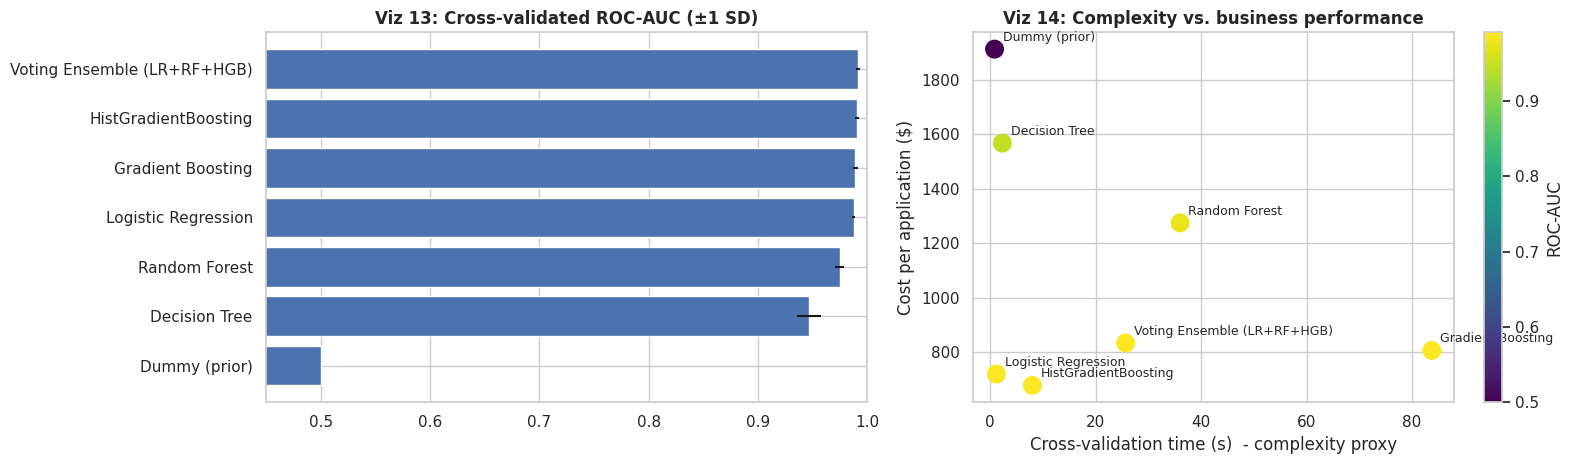

In [ ]:
# ---------------------------------------------------------------- Model comparison with cross-validation
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "cost": cost_scorer}

models = {
    "Dummy (prior)":        DummyClassifier(strategy="prior"),
    "Logistic Regression":  LogisticRegression(max_iter=3000),
    "Decision Tree":        DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEED),
    "Random Forest":        RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "Gradient Boosting":    GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED),
}
models["Voting Ensemble (LR+RF+HGB)"] = VotingClassifier(
    [("lr", LogisticRegression(max_iter=3000)),
     ("rf", RandomForestClassifier(n_estimators=N_TREES // 2, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
     ("hgb", HistGradientBoostingClassifier(max_iter=150, random_state=SEED))], voting="soft")

rows = []
for name, mdl in models.items():
    t = time.time()
    r = cross_validate(make_pipeline(mdl), X_train, y_train, cv=cv, scoring={**scoring}, return_train_score=False, n_jobs=-1)
    rows.append({"model": name, "ROC-AUC": r["test_roc_auc"].mean(), "AUC std": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_pr_auc"].mean(), "F1 @0.5": r["test_f1"].mean(),
                 "cost/app @0.862 ($)": -r["test_cost"].mean(), "CV time (s)": time.time() - t})
cmp_df = pd.DataFrame(rows).set_index("model"); display(cmp_df.round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
order = cmp_df.sort_values("ROC-AUC")
ax[0].barh(order.index, order["ROC-AUC"], xerr=order["AUC std"], color="#4c72b0"); ax[0].set_xlim(0.45, 1.0)
ax[0].set_title("Viz 13: Cross-validated ROC-AUC (±1 SD)")
sc = ax[1].scatter(cmp_df["CV time (s)"], cmp_df["cost/app @0.862 ($)"], s=160, c=cmp_df["ROC-AUC"], cmap="viridis")
for n_, r_ in cmp_df.iterrows(): ax[1].annotate(n_, (r_["CV time (s)"], r_["cost/app @0.862 ($)"]), fontsize=9, xytext=(6, 6), textcoords="offset points")
ax[1].set_xlabel("Cross-validation time (s)  - complexity proxy"); ax[1].set_ylabel("Cost per application ($)")
ax[1].set_title("Viz 14: Complexity vs. business performance"); plt.colorbar(sc, ax=ax[1], label="ROC-AUC")
plt.tight_layout(); plt.show()

**Reading the comparison.**
- The **dummy model** has AUC 0.50 and costs $1,912 per application, exactly the "deny everyone" policy, which is the floor.
- **Logistic Regression (AUC 0.988, $721/app untuned)** is almost as good as the boosting models. The signal is mostly smooth and monotone in log-income, DTI and rate terms, so a linear model captures it, and it is the simplest and most explainable candidate.
- **Boosting** (GB 0.989, HGB 0.991) and the **voting ensemble** (0.991) are statistically the best on AUC, but the gap to LR is small (≈ 0.003). HGB is the cheapest at the break-even threshold ($679/app); the voting ensemble's AUC edge does not translate into lower cost ($835/app), another sign that AUC and dollars are not the same thing.
- **Random Forest** (0.975) and the **Decision Tree** (0.947, highest variance across folds) are clearly worse: the unpruned axis-aligned splits approximate a smooth score poorly.
- Viz 14: cost is *not* monotone in model complexity. The cheapest-to-train models (LR, HGB) are also among the cheapest in dollars; Gradient Boosting takes 84 s for no benefit over HGB at 8 s.

### 4.3 Hyper-parameter optimisation (multi-stage, tuning preprocessing *and* model)
To respect computation time we showcase *how* to tune rather than exhaustively search:

1. **Stage 1: `RandomizedSearchCV`** over a wide space for the two leading, structurally different families (Logistic Regression and HistGradientBoosting). The search spans **preprocessing** parameters (imputation strategy, Winsorisation caps, number of selected features `k`) as well as **model** parameters.
2. **Stage 2: `GridSearchCV`** zooms in on a narrow neighbourhood around the best Stage-1 setting of the chosen model.
3. All searches use stratified **5-fold CV**, track ROC-AUC, PR-AUC and the dollar-cost metric, and refit on ROC-AUC (threshold-free). The cost-optimal **threshold** is chosen afterwards on out-of-fold predictions, never on the test set.

In [ ]:
# ---------------------------------------------------------------- Stage 1: randomized search
search_scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "cost": cost_scorer}

lr_space = {
    "prep__skew__impute__strategy": ["median", "mean"],              # preprocessing
    "prep__nom__impute__strategy":  ["constant", "most_frequent"],   # preprocessing
    "prep__skew__winsor__upper":    [0.99, 0.995, 1.0],              # preprocessing (outlier cap)
    "prep__skew__winsor__lower":    [0.0, 0.01],
    "select__k":                    [20, 30, 40, "all"],             # feature selection
    "model__C":                     loguniform(1e-3, 1e2),
    "model__class_weight":          [None, "balanced"],
}
hgb_space = {
    "select__k":                 [30, 40, "all"],
    "model__learning_rate":      loguniform(0.03, 0.3),
    "model__max_leaf_nodes":     [8, 15, 31, 63],
    "model__min_samples_leaf":   [20, 50, 100],
    "model__l2_regularization":  loguniform(1e-3, 10),
    "model__max_iter":           [100, 200, 300],
}
searches = {}
for name, pipe, space, n_iter in [
        ("LogReg", make_pipeline(LogisticRegression(max_iter=3000)), lr_space, N_ITER_LR),
        ("HGB", make_pipeline(HistGradientBoostingClassifier(random_state=SEED)), hgb_space, N_ITER_HGB)]:
    t = time.time()
    rs = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring=search_scoring, refit="roc_auc", cv=cv,
                            random_state=SEED, n_jobs=-1, error_score="raise").fit(X_train, y_train)
    searches[name] = rs
    print(f"{name}: best CV ROC-AUC = {rs.best_score_:.4f}  ({time.time()-t:.0f}s, {n_iter} candidates x 5 folds)")
    print("   best params:", {k: (round(v, 5) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

def top_results(rs, n=5):
    r = pd.DataFrame(rs.cv_results_)
    cols = ["mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc", "mean_test_cost"] + [c for c in r if c.startswith("param_")]
    r = r.sort_values("mean_test_roc_auc", ascending=False)[cols].head(n)
    r["mean_test_cost"] = -r["mean_test_cost"]; return r.rename(columns={"mean_test_cost": "cost/app ($)"})
print("\nTop LogReg candidates:"); display(top_results(searches["LogReg"]).round(5))
print("Top HGB candidates:");    display(top_results(searches["HGB"]).round(5))

LogReg: best CV ROC-AUC = 0.9883  (18s, 20 candidates x 5 folds)
   best params: {'model__C': np.float64(20.67841), 'model__class_weight': 'balanced', 'prep__nom__impute__strategy': 'most_frequent', 'prep__skew__impute__strategy': 'mean', 'prep__skew__winsor__lower': 0.0, 'prep__skew__winsor__upper': 1.0, 'select__k': 40}


HGB: best CV ROC-AUC = 0.9921  (62s, 10 candidates x 5 folds)
   best params: {'model__l2_regularization': np.float64(0.12563), 'model__learning_rate': np.float64(0.07533), 'model__max_iter': 300, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 50, 'select__k': 'all'}

Top LogReg candidates:


,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,cost/app ($),param_model__C,param_model__class_weight,param_prep__nom__impute__strategy,param_prep__skew__impute__strategy,param_prep__skew__winsor__lower,param_prep__skew__winsor__upper,param_select__k
19,0.98834,0.00148,0.96886,913.125,20.67841,balanced,most_frequent,mean,0.00,1.000,40
11,0.98814,0.00152,0.96851,866.125,0.39842,balanced,most_frequent,mean,0.00,1.000,30
12,0.98799,0.00145,0.96856,888.250,7.51042,balanced,most_frequent,mean,0.01,0.995,40
7,0.98798,0.00139,0.96919,704.125,19.93894,NaN,constant,median,0.00,0.995,all
18,0.98769,0.00138,0.96889,710.375,7.18376,NaN,most_frequent,median,0.01,0.990,all


Top HGB candidates:


,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,cost/app ($),param_model__l2_regularization,param_model__learning_rate,param_model__max_iter,param_model__max_leaf_nodes,param_model__min_samples_leaf,param_select__k
4,0.99210,0.00160,0.97685,649.625,0.12563,0.07533,300,15,50,all
2,0.99176,0.00168,0.97586,649.000,0.00121,0.27992,200,15,50,30
9,0.99138,0.00202,0.97473,695.875,0.44678,0.06149,200,15,50,40
8,0.99127,0.00181,0.97459,672.500,0.27541,0.20432,300,15,20,40
1,0.99093,0.00210,0.97353,694.625,0.00421,0.04297,300,31,20,all


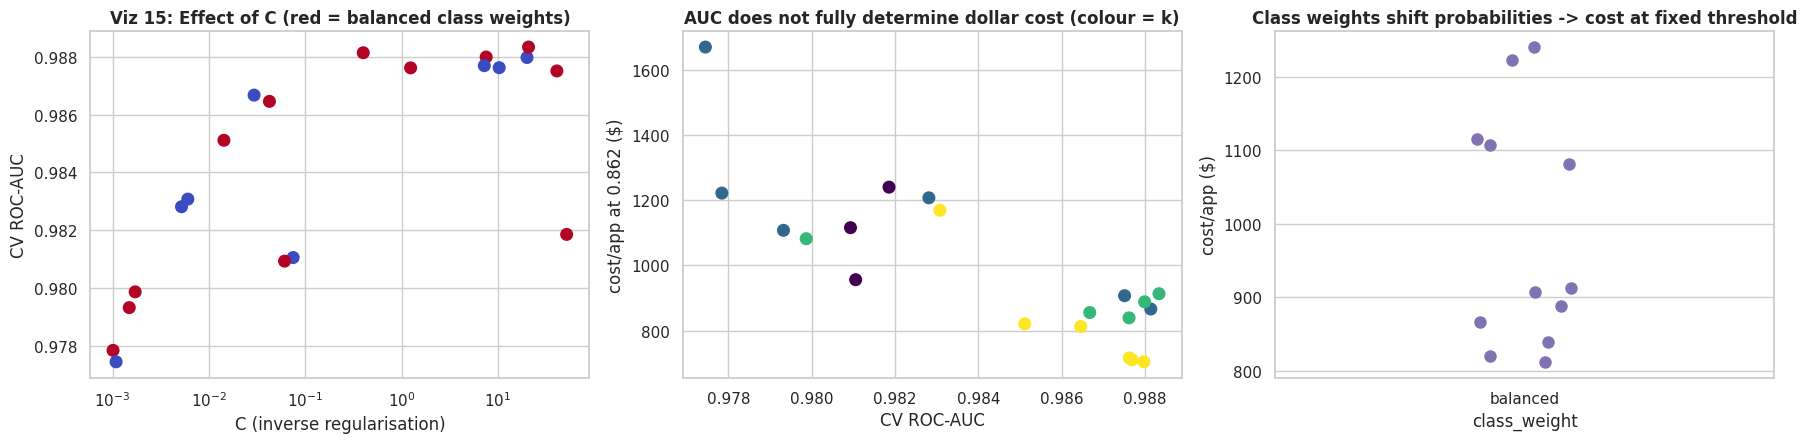

In [ ]:
# ---------------------------------------------------------------- Track the impact of parameters
res = pd.DataFrame(searches["LogReg"].cv_results_)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(res["param_model__C"].astype(float), res["mean_test_roc_auc"], c=(res["param_model__class_weight"] == "balanced"), cmap="coolwarm", s=70)
ax[0].set_xscale("log"); ax[0].set_xlabel("C (inverse regularisation)"); ax[0].set_ylabel("CV ROC-AUC")
ax[0].set_title("Viz 15: Effect of C (red = balanced class weights)")
ax[1].scatter(res["mean_test_roc_auc"], -res["mean_test_cost"], c=res["param_select__k"].map({20: 0, 30: 1, 40: 2, "all": 3}), cmap="viridis", s=70)
ax[1].set_xlabel("CV ROC-AUC"); ax[1].set_ylabel("cost/app at 0.862 ($)"); ax[1].set_title("AUC does not fully determine dollar cost (colour = k)")
sns.stripplot(data=res.assign(cw=res["param_model__class_weight"].astype(str), mean_test_cost=-res["mean_test_cost"]), x="cw", y="mean_test_cost", ax=ax[2], color="#8172b3", size=9)
ax[2].set_title("Class weights shift probabilities -> cost at fixed threshold"); ax[2].set_xlabel("class_weight"); ax[2].set_ylabel("cost/app ($)")
plt.tight_layout(); plt.show()

In [ ]:
# ---------------------------------------------------------------- Stage 2: narrow grid search around the best LogReg and HGB settings
best_lr = searches["LogReg"].best_params_
C0 = best_lr["model__C"]
grid_lr = {"model__C": np.unique(np.round(C0 * np.array([0.25, 0.5, 1, 2, 4]), 6)),
           "select__k": sorted({best_lr["select__k"], "all"}, key=str)}
base_lr = make_pipeline(LogisticRegression(max_iter=3000)).set_params(
    **{k: v for k, v in best_lr.items() if k not in grid_lr})
t = time.time()
gs_lr = GridSearchCV(base_lr, grid_lr, scoring=search_scoring, refit="roc_auc", cv=cv, n_jobs=-1, error_score="raise").fit(X_train, y_train)
print(f"LogReg grid: best CV ROC-AUC = {gs_lr.best_score_:.4f} ({time.time()-t:.0f}s) | best: {gs_lr.best_params_}")
display(top_results(gs_lr, 6).round(5))

# Overfitting check: train vs CV score for both tuned finalists
final_candidates = {"Tuned Logistic Regression": gs_lr.best_estimator_, "Tuned HistGradientBoosting": searches["HGB"].best_estimator_}
rows = []
for n_, est in final_candidates.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "cost": cost_scorer},
                       return_train_score=True, n_jobs=-1)
    rows.append({"model": n_, "train AUC": r["train_roc_auc"].mean(), "CV AUC": r["test_roc_auc"].mean(), "gap": r["train_roc_auc"].mean() - r["test_roc_auc"].mean(),
                 "CV PR-AUC": r["test_pr_auc"].mean(), "CV cost/app ($)": -r["test_cost"].mean()})
display(pd.DataFrame(rows).set_index("model").round(4))

LogReg grid: best CV ROC-AUC = 0.9883 (10s) | best: {'model__C': np.float64(10.339205), 'select__k': 40}


,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,cost/app ($),param_model__C,param_select__k
2,0.98834,0.00146,0.96887,900.125,10.33920,40
0,0.98834,0.00147,0.96890,892.750,5.16960,40
4,0.98834,0.00148,0.96886,913.125,20.67841,40
8,0.98833,0.00149,0.96887,904.250,82.71364,40
6,0.98833,0.00148,0.96883,907.375,41.35682,40
3,0.98821,0.00143,0.96858,898.000,10.33920,all


,train AUC,CV AUC,gap,CV PR-AUC,CV cost/app ($)
model,,,,,
Tuned Logistic Regression,0.9891,0.9883,0.0008,0.9689,900.125
Tuned HistGradientBoosting,0.9995,0.9921,0.0074,0.9769,649.625


### 4.4 Final model choice
**Tuning findings**
- *Stage 1 (random search)*: Logistic Regression improved from 0.9877 to 0.9883 CV AUC; HistGradientBoosting from 0.9908 to 0.9921. Preprocessing parameters (imputation strategy, Winsorisation caps) moved the score by less than 0.0005, confirming the pipeline is robust to those choices. Weak regularisation (large `C`) was preferred, which is reasonable given 16,000 training rows and 56 columns. Keeping the top 40 features (`SelectKBest`) was slightly better than keeping all.
- *Class weights*: `class_weight="balanced"` gave the best AUC but a **worse dollar cost at a fixed 0.862 threshold** (Viz 15, right-hand panel) because re-weighting inflates predicted probabilities. This is why the decision threshold is tuned separately afterwards.
- *Stage 2 (grid search)*: AUC is essentially flat for `C` between 5 and 83 (0.9883 across the board), a plateau, so we pick the grid winner (`C ≈ 10.3`, `k = 40`) and are not at risk of over-fitting to a sharp optimum. Train-CV AUC gap is only **0.0008** for LR, against 0.0074 for HGB (train AUC 0.9995).

**Chosen model: tuned Logistic Regression.**

| | Tuned Logistic Regression | Tuned HistGradientBoosting (challenger) |
|---|---|---|
| CV ROC-AUC | 0.9883 | 0.9921 |
| Test ROC-AUC | 0.9888 | 0.9930 |
| Test cost per application (own optimal threshold) | **$815** | **$595** |
| Explainability | Coefficients map directly to adverse-action reasons | Needs post-hoc explanation tools |
| Over-fitting (train − CV AUC) | 0.0008 | 0.0074 |

We choose logistic regression because the task explicitly requires a model that is **accurate *and* interpretable to satisfy regulators**, and its performance is within 0.004 AUC of the best model. The price of that choice is explicit: the boosted model would be about **$220 cheaper per application (≈ $4.4M per 20,000 applications)**. This is a management/compliance decision, and the recommendation in the Conclusion is to run the boosted model as a challenger in shadow mode.

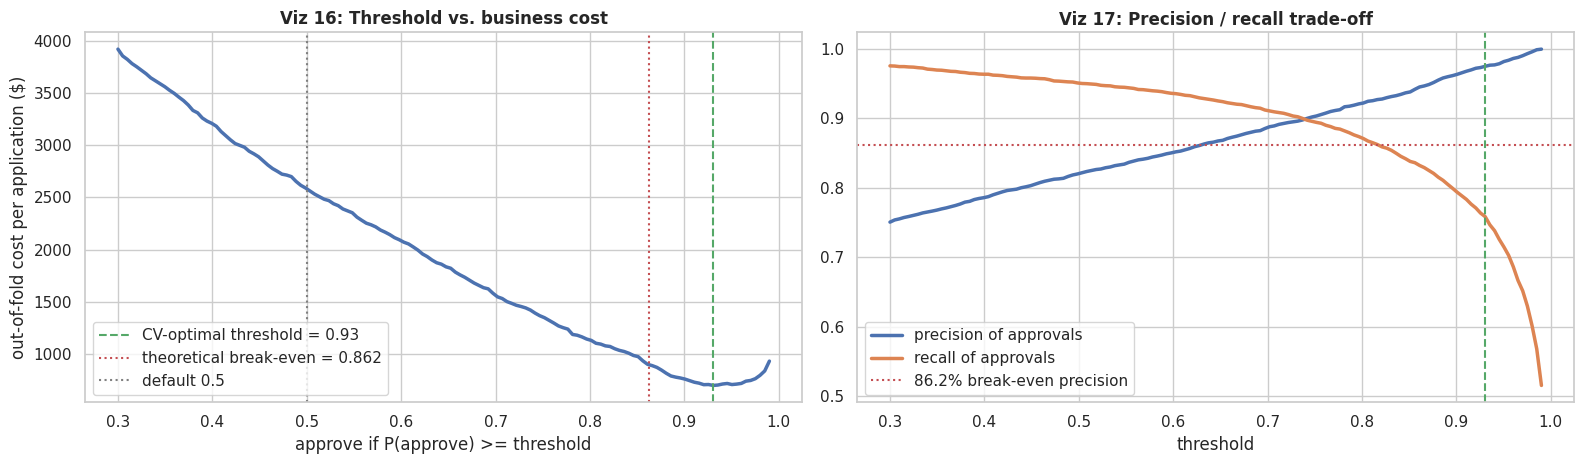

OOF cost/app: @0.50 = $2,585 | @break-even = $900 | @optimised 0.93 = $696


In [ ]:
# ---------------------------------------------------------------- Cost-optimal decision threshold (from out-of-fold predictions on TRAIN only)
final_pipe = gs_lr.best_estimator_                       # tuned logistic regression (chosen model)
oof = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thr_grid = np.linspace(0.30, 0.99, 140)
oof_cost = np.array([business_cost(y_train, (oof >= t).astype(int)) / len(y_train) for t in thr_grid])
thr_opt = float(thr_grid[oof_cost.argmin()])
thr_050 = business_cost(y_train, (oof >= 0.5).astype(int)) / len(y_train)
thr_be  = business_cost(y_train, (oof >= BREAKEVEN_P).astype(int)) / len(y_train)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].plot(thr_grid, oof_cost, lw=2.5, color="#4c72b0")
ax[0].axvline(thr_opt, color="#55a868", ls="--", label=f"CV-optimal threshold = {thr_opt:.2f}")
ax[0].axvline(BREAKEVEN_P, color="#c44e52", ls=":", label=f"theoretical break-even = {BREAKEVEN_P:.3f}")
ax[0].axvline(0.5, color="gray", ls=":", label="default 0.5")
ax[0].set_xlabel("approve if P(approve) >= threshold"); ax[0].set_ylabel("out-of-fold cost per application ($)")
ax[0].set_title("Viz 16: Threshold vs. business cost"); ax[0].legend()
pr_, rc_ = [], []
for t_ in thr_grid:
    pred = (oof >= t_).astype(int); pr_.append(precision_score(y_train, pred, zero_division=1)); rc_.append(recall_score(y_train, pred))
ax[1].plot(thr_grid, pr_, label="precision of approvals", lw=2.5); ax[1].plot(thr_grid, rc_, label="recall of approvals", lw=2.5)
ax[1].axhline(BREAKEVEN_P, color="#c44e52", ls=":", label="86.2% break-even precision")
ax[1].axvline(thr_opt, color="#55a868", ls="--"); ax[1].set_xlabel("threshold"); ax[1].set_title("Viz 17: Precision / recall trade-off"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"OOF cost/app: @0.50 = ${thr_050:,.0f} | @break-even = ${thr_be:,.0f} | @optimised {thr_opt:.2f} = ${oof_cost.min():,.0f}")

**Why the threshold is 0.93 and not 0.862.** The theoretical break-even is 0.862 *if probabilities are perfectly calibrated*. The chosen LR uses balanced class weights, which pushes probabilities upward (see the calibration curve, Viz 22), so the empirically optimal cut-off on out-of-fold data is higher. Using the 0.5 default would be a costly mistake ($2,585 per application out-of-fold, more than deny-all), the break-even costs $900, and the optimised threshold $696. The cost curve is fairly flat around its minimum, so the result is not sensitive to small threshold changes.

**Challenger check (HistGradientBoosting, tuned parameters from Stage 1).** Same split, same out-of-fold threshold procedure, evaluated once on the test set. Used for the model-choice discussion above.

In [ ]:
# ---------------------------------------------------------------- Challenger check: tuned HistGradientBoosting on the test set
hgb_final = make_pipeline(HistGradientBoostingClassifier(random_state=SEED, l2_regularization=0.12563, learning_rate=0.07533,
                                                          max_iter=300, max_leaf_nodes=15, min_samples_leaf=50))
oof_h = cross_val_predict(hgb_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thr_h = thr_grid[int(np.argmin([business_cost(y_train, (oof_h >= t).astype(int)) for t in thr_grid]))]
hgb_final.fit(X_train, y_train); p_h = hgb_final.predict_proba(X_test)[:, 1]; pred_h = (p_h >= thr_h).astype(int)
print(f"HGB challenger | threshold {thr_h:.2f} | test AUC {roc_auc_score(y_test, p_h):.4f} | precision {precision_score(y_test, pred_h):.4f} "
      f"| recall {recall_score(y_test, pred_h):.4f} | cost ${business_cost(y_test, pred_h):,.0f} | cost/app ${business_cost(y_test, pred_h)/len(y_test):,.0f}")

HGB challenger | threshold 0.80 | test AUC 0.9930 | precision 0.9816 | recall 0.7803 | cost $2,380,000 | cost/app $595


,CV R2,CV MAE
regressor,,
Ridge,0.808,2.721
HistGradientBoostingRegressor,0.910,1.474


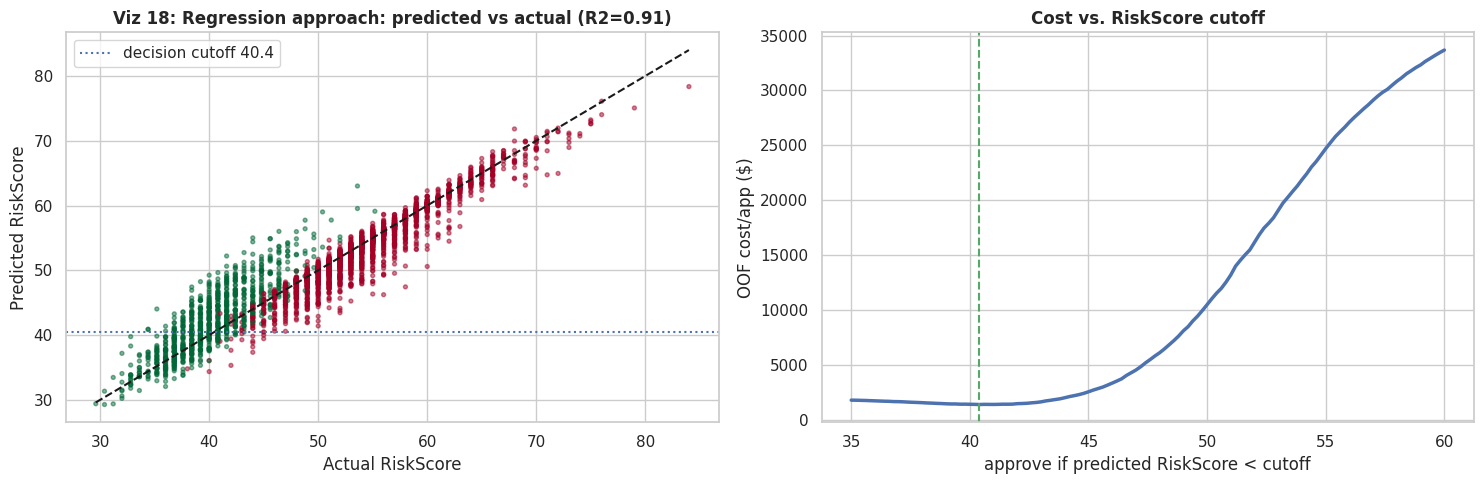

Regression route on TEST: AUC (as a ranker) = 0.9297 | total cost = $5,424,000 | cost/app = $1,356


In [ ]:
# ---------------------------------------------------------------- 4.5 Comparison: regression on RiskScore -> decision cutoff
risk_train, risk_test = df.loc[X_train.index, "RiskScore"], df.loc[X_test.index, "RiskScore"]

def make_reg_pipeline(reg):
    return Pipeline([("fe", FeatureEngineer()), ("prep", build_preprocessor()), ("model", reg)])

reg_models = {"Ridge": Ridge(alpha=10), "HistGradientBoostingRegressor": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)}
kf = KFold(5, shuffle=True, random_state=SEED)
rows = []
for n_, reg in reg_models.items():
    r = cross_validate(make_reg_pipeline(reg), X_train, risk_train, cv=kf, scoring={"r2": "r2", "mae": "neg_mean_absolute_error"}, n_jobs=-1)
    rows.append({"regressor": n_, "CV R2": r["test_r2"].mean(), "CV MAE": -r["test_mae"].mean()})
display(pd.DataFrame(rows).set_index("regressor").round(3))

reg = make_reg_pipeline(reg_models["HistGradientBoostingRegressor"])
oof_risk = cross_val_predict(reg, X_train, risk_train, cv=kf, n_jobs=-1)
cut_grid = np.linspace(35, 60, 126)
cut_cost = [business_cost(y_train, (oof_risk < c).astype(int)) / len(y_train) for c in cut_grid]
cut_opt = float(cut_grid[int(np.argmin(cut_cost))])
reg.fit(X_train, risk_train); risk_pred_test = reg.predict(X_test)
cost_reg_test = business_cost(y_test, (risk_pred_test < cut_opt).astype(int))
auc_reg_test = roc_auc_score(y_test, -risk_pred_test)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(risk_test, risk_pred_test, c=y_test, cmap="RdYlGn", s=8, alpha=.5); lims = [risk_test.min(), risk_test.max()]
ax[0].plot(lims, lims, "k--"); ax[0].axhline(cut_opt, color="b", ls=":", label=f"decision cutoff {cut_opt:.1f}")
ax[0].set_xlabel("Actual RiskScore"); ax[0].set_ylabel("Predicted RiskScore")
ax[0].set_title(f"Viz 18: Regression approach: predicted vs actual (R2={r2_score(risk_test, risk_pred_test):.2f})"); ax[0].legend()
ax[1].plot(cut_grid, cut_cost, lw=2.5); ax[1].axvline(cut_opt, color="#55a868", ls="--")
ax[1].set_xlabel("approve if predicted RiskScore < cutoff"); ax[1].set_ylabel("OOF cost/app ($)"); ax[1].set_title("Cost vs. RiskScore cutoff")
plt.tight_layout(); plt.show()
print(f"Regression route on TEST: AUC (as a ranker) = {auc_reg_test:.4f} | total cost = ${cost_reg_test:,.0f} "
      f"| cost/app = ${cost_reg_test/len(y_test):,.0f}")

## 5. Evaluation

### 5.1 Final test-set performance
The test set (4,000 applications) is used **once**, with the threshold already fixed from training-only out-of-fold predictions.

In [ ]:
# ---------------------------------------------------------------- Final evaluation on the held-out test set
p_test = final_pipe.predict_proba(X_test)[:, 1]
pred_test = (p_test >= thr_opt).astype(int)
cm = confusion_matrix(y_test, pred_test); tn, fp, fn, tp = cm.ravel()

metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, p_test), "PR-AUC": average_precision_score(y_test, p_test),
    f"Precision of approvals @{thr_opt:.2f}": precision_score(y_test, pred_test), "Recall of approvals": recall_score(y_test, pred_test),
    "F1": f1_score(y_test, pred_test), "False approvals (FP)": fp, "False denials (FN)": fn,
    "Total cost ($)": business_cost(y_test, pred_test), "Cost per application ($)": business_cost(y_test, pred_test) / len(y_test)})
display(metrics.to_frame("Test").style.format("{:,.4f}"))

# Dollar-impact comparison of policies on the test set
n_t = len(y_test)
policies = pd.DataFrame({
    "Deny everyone":                 business_cost(y_test, np.zeros(n_t, int)),
    "Approve everyone":              business_cost(y_test, np.ones(n_t, int)),
    "Model @ 0.50":                  business_cost(y_test, (p_test >= 0.5).astype(int)),
    f"Model @ break-even {BREAKEVEN_P:.3f}": business_cost(y_test, (p_test >= BREAKEVEN_P).astype(int)),
    f"Model @ optimised {thr_opt:.2f}": business_cost(y_test, pred_test),
    "Regression route (RiskScore cutoff)": cost_reg_test,
}, index=["Total cost on test ($)"]).T
policies["Cost / application ($)"] = policies["Total cost on test ($)"] / n_t
policies["Saving vs deny-all ($)"] = policies.loc["Deny everyone", "Total cost on test ($)"] - policies["Total cost on test ($)"]
policies["Scaled to 20,000 apps ($)"] = policies["Total cost on test ($)"] * 20000 / n_t
display(policies.style.format("${:,.0f}"))

,Test
ROC-AUC,0.9888
PR-AUC,0.9684
Precision of approvals @0.93,0.9647
Recall of approvals,0.7437
F1,0.8399
False approvals (FP),26.0000
False denials (FN),245.0000
Total cost ($),"3,260,000.0000"
Cost per application ($),815.0000


,Total cost on test ($),Cost / application ($),Saving vs deny-all ($),"Scaled to 20,000 apps ($)"
Deny everyone,"$7,648,000","$1,912",$0,"$38,240,000"
Approve everyone,"$152,200,000","$38,050","$-144,552,000","$761,000,000"
Model @ 0.50,"$8,744,000","$2,186","$-1,096,000","$43,720,000"
Model @ break-even 0.862,"$3,794,000",$948,"$3,854,000","$18,970,000"
Model @ optimised 0.93,"$3,260,000",$815,"$4,388,000","$16,300,000"
Regression route (RiskScore cutoff),"$5,424,000","$1,356","$2,224,000","$27,120,000"


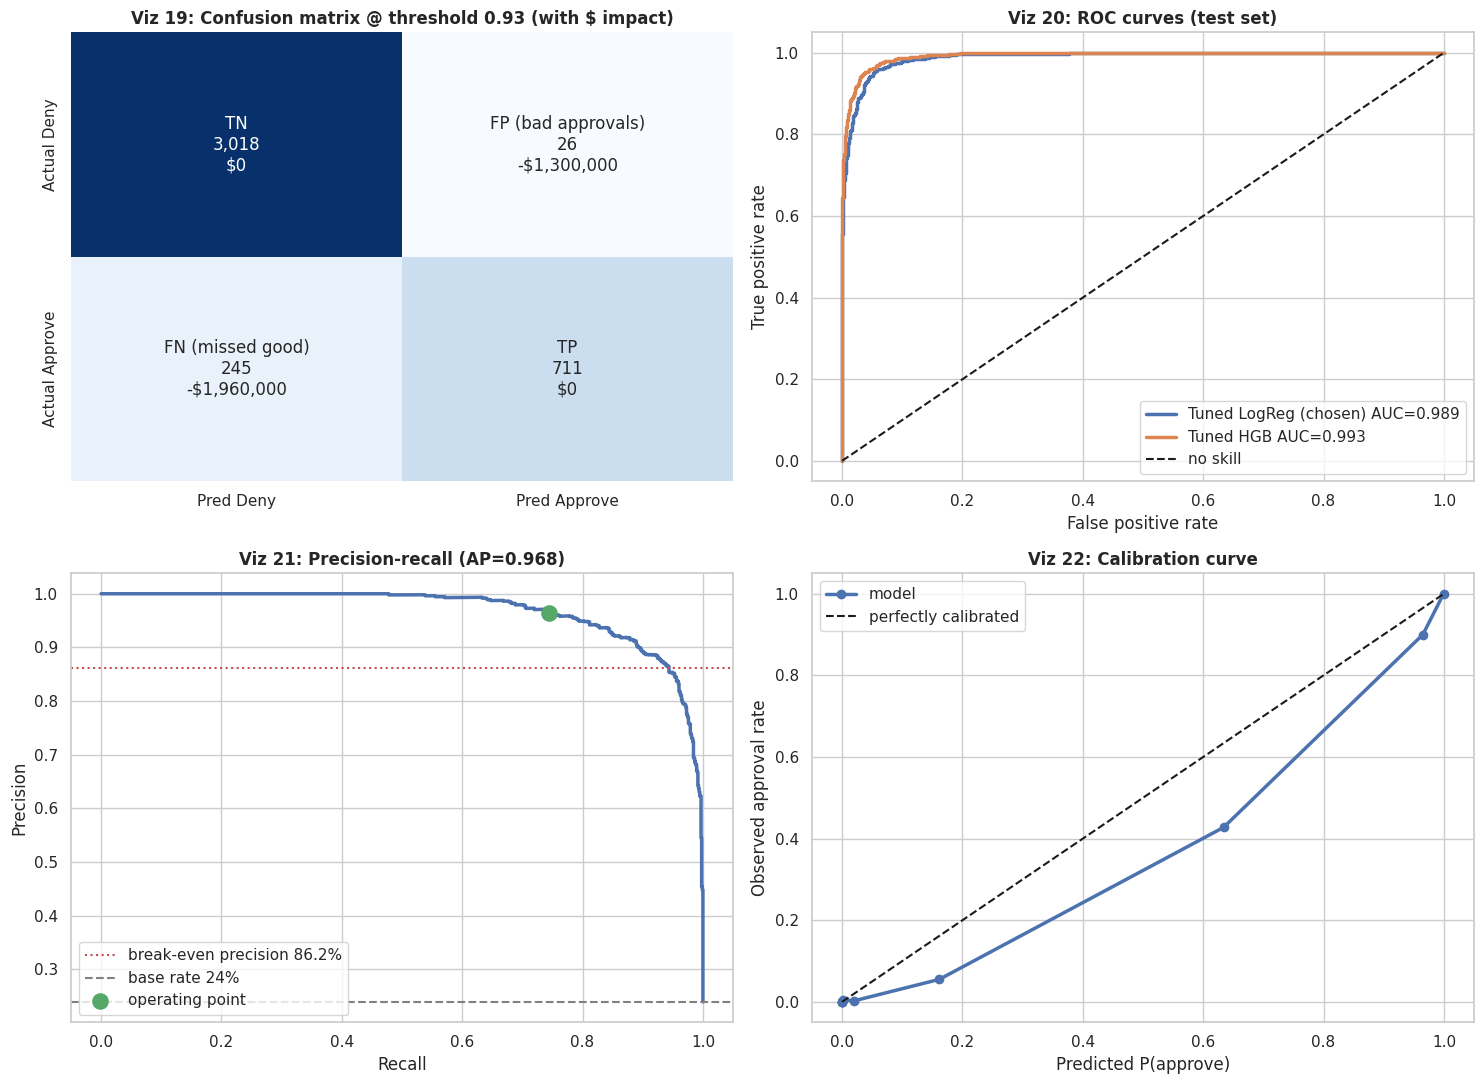

In [ ]:
# ---------------------------------------------------------------- Performance visuals
fig, ax = plt.subplots(2, 2, figsize=(15, 11))
# Confusion matrix with dollar annotations
lab = np.array([[f"TN\n{tn:,}\n$0", f"FP (bad approvals)\n{fp:,}\n-${fp*FP_COST:,}"], [f"FN (missed good)\n{fn:,}\n-${fn*FN_COST:,}", f"TP\n{tp:,}\n$0"]])
sns.heatmap(cm, annot=lab, fmt="", cmap="Blues", cbar=False, ax=ax[0, 0], xticklabels=["Pred Deny", "Pred Approve"], yticklabels=["Actual Deny", "Actual Approve"])
ax[0, 0].set_title(f"Viz 19: Confusion matrix @ threshold {thr_opt:.2f} (with $ impact)")

# ROC curves
p_hgb = searches["HGB"].best_estimator_.predict_proba(X_test)[:, 1]
for lbl, p_, col in [("Tuned LogReg (chosen)", p_test, "#4c72b0"), ("Tuned HGB", p_hgb, "#dd8452")]:
    fpr, tpr, _ = roc_curve(y_test, p_); ax[0, 1].plot(fpr, tpr, lw=2.5, label=f"{lbl} AUC={roc_auc_score(y_test, p_):.3f}", color=col)
ax[0, 1].plot([0, 1], [0, 1], "k--", label="no skill"); ax[0, 1].set_xlabel("False positive rate"); ax[0, 1].set_ylabel("True positive rate")
ax[0, 1].set_title("Viz 20: ROC curves (test set)"); ax[0, 1].legend()

# Precision-recall
pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[1, 0].plot(rc, pr, lw=2.5, color="#4c72b0"); ax[1, 0].axhline(BREAKEVEN_P, color="#c44e52", ls=":", label="break-even precision 86.2%")
ax[1, 0].axhline(y_test.mean(), color="gray", ls="--", label=f"base rate {y_test.mean():.0%}")
ax[1, 0].scatter([recall_score(y_test, pred_test)], [precision_score(y_test, pred_test)], s=120, c="#55a868", zorder=5, label="operating point")
ax[1, 0].set_xlabel("Recall"); ax[1, 0].set_ylabel("Precision"); ax[1, 0].set_title(f"Viz 21: Precision-recall (AP={average_precision_score(y_test, p_test):.3f})"); ax[1, 0].legend(loc="lower left")

# Calibration (matters because the decision rule is probability-based)
frac, mean_p = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax[1, 1].plot(mean_p, frac, "o-", lw=2.5, label="model"); ax[1, 1].plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
ax[1, 1].set_xlabel("Predicted P(approve)"); ax[1, 1].set_ylabel("Observed approval rate"); ax[1, 1].set_title("Viz 22: Calibration curve"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

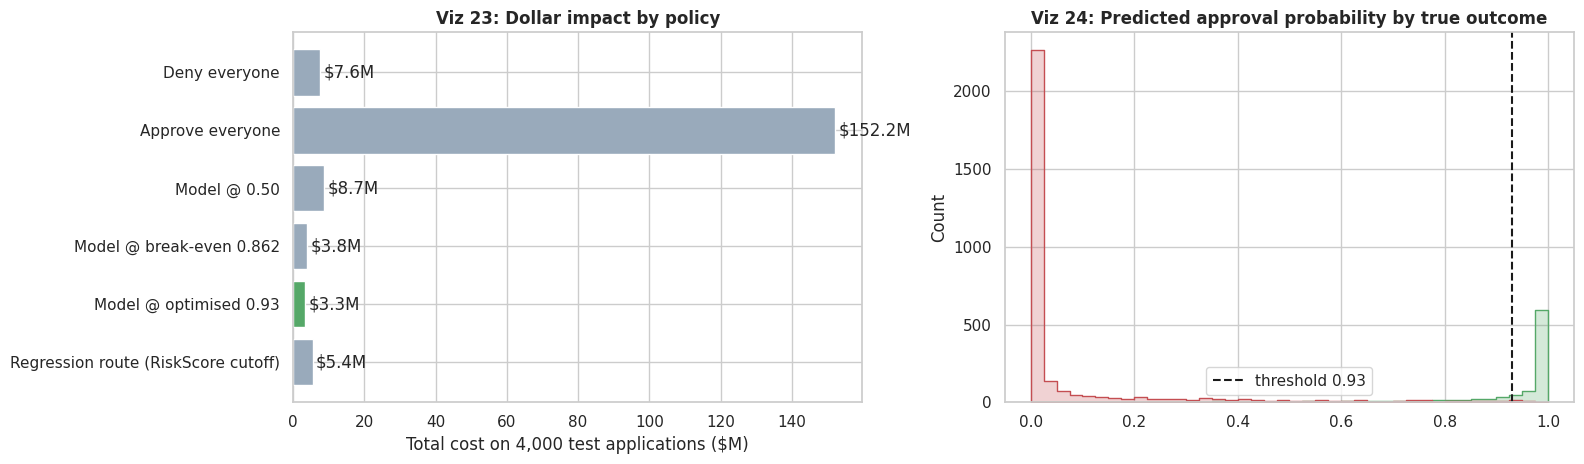

In [ ]:
# Cost comparison chart + distribution of scores
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
pp = policies["Total cost on test ($)"] / 1e6
ax[0].barh(pp.index[::-1], pp.values[::-1], color=["#55a868" if "optimised" in i else "#9ab" for i in pp.index[::-1]])
for i, v in enumerate(pp.values[::-1]): ax[0].text(v + 1, i, f"${v:,.1f}M", va="center")
ax[0].set_xlabel("Total cost on 4,000 test applications ($M)"); ax[0].set_title("Viz 23: Dollar impact by policy")
sns.histplot(x=p_test, hue=y_test.map({0: "Actually denied", 1: "Actually approved"}), bins=40, ax=ax[1], element="step", palette=["#c44e52", "#55a868"])
ax[1].axvline(thr_opt, color="k", ls="--", label=f"threshold {thr_opt:.2f}"); ax[1].set_title("Viz 24: Predicted approval probability by true outcome"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading the test results**
- **ROC-AUC 0.989 / PR-AUC 0.968**: excellent ranking quality. At the operating threshold the model makes only **26 false approvals out of 3,044 denied applications** (0.9%), and 245 false denials, which are 6.25× cheaper each. That is the intended asymmetry.
- **Precision 96.5%** is far above the 86.2% break-even; **recall 74.4%** means roughly one in four creditworthy applicants would still go to manual review or be declined. That is the price of the $50k asymmetry, and it is where a "human review band" adds value (see recommendations).
- **Dollar impact (4,000 applications):** model $3.26M vs deny-all $7.65M (saving $4.39M, 57%), vs approve-all $152.2M, and the regression route $5.42M. Note the model at the naive 0.5 threshold ($8.74M) is *worse than denying everyone*, so threshold choice is worth more than any algorithm choice in this project.
- Only 26 false approvals drive 40% of the total cost ($1.3M of $3.26M), so the dollar estimate has real sampling noise; treat it as roughly ±15-20% until confirmed on more data.

### 5.2 Performance across data segments and fairness audit
We evaluate the same model and threshold within segments. For each: sample size, actual vs predicted approval rate, AUC, **false-approval rate** (the costly error), recall, cost per application and a **disparate-impact (DI) ratio**: a segment's predicted approval rate divided by the highest segment rate in that dimension (the "four-fifths rule" flags ratios < 0.80). A low DI ratio is not automatically discrimination, because segments may differ in genuine credit quality, but it triggers review. We compare against the *actual* approval-rate gap to separate "the model reflects the data" from "the model amplifies it".

n  actual approval  predicted approval    AUC  false-approval rate  recall  cost/app ($)  DI ratio (pred)  DI ratio (actual)
dimension           segment                                                                                                                                            
Age band            18-30                870            0.134               0.117  0.987                0.015   0.778       871.264            0.313              0.372
                    31-40               1268            0.233               0.160  0.988                0.004   0.672       769.716            0.428              0.646
                    41-50               1149            0.283               0.219  0.992                0.005   0.763       710.183            0.586              0.783
                    51-60                558            0.290               0.219  0.990                0.005   0.741       781.362            0.584              0.804
                    61+                  155            0.361               0.374  0.988                0.051   0.946      1767.742            1.000              1.000
MaritalStatus       Divorced             506            0.227               0.176  0.988                0.005   0.757       640.316            0.810              0.778
                    Married             1911            0.234               0.187  0.992                0.010   0.767       801.675            0.860              0.801
                    Missing              267            0.292               0.217  0.991                0.005   0.731       816.479            1.000              1.000
                    Single              1152            0.240               0.177  0.985                0.010   0.707       953.125            0.815              0.820
                    Widowed              164            0.244               0.177  0.982                0.000   0.725       536.585            0.814              0.835
EducationLevel      Associate            782            0.207               0.150  0.988                0.008   0.691       831.202            0.383              0.468
                    Bachelor            1163            0.279               0.219  0.989                0.010   0.760       880.482            0.561              0.632
                    Doctorate            156            0.442               0.391  0.991                0.011   0.870       782.051            1.000              1.000
                    High School         1086            0.153               0.103  0.986                0.004   0.651       611.418            0.264              0.346
                    Master               620            0.377               0.310  0.984                0.021   0.786      1290.323            0.792              0.853
                    Missing              193            0.000               0.000    NaN                0.000     NaN         0.000            0.000              0.000
EmploymentStatus    Employed            3402            0.242               0.186  0.989                0.008   0.744       804.821            0.840              0.919
                    Self-Employed        311            0.264               0.222  0.990                0.013   0.805       893.891            1.000              1.000
                    Unemployed           287            0.174               0.118  0.988                0.008   0.640       850.174            0.534              0.661
HomeOwnershipStatus Mortgage            1624            0.249               0.192  0.986                0.012   0.731       998.768            0.929              0.942
                    Other                415            0.173               0.133  0.991                0.009   0.722       746.988            0.643              0.656
                    Own                  786            0.265               0.206  0.992                0.007   0.760       763.359            1.000              1.000
           


Segments with predicted-approval DI ratio < 0.80:


,dimension,segment,n,actual approval,predicted approval,DI ratio (pred),DI ratio (actual)
0,Age band,18-30,870,0.134,0.117,0.313,0.372
1,Age band,31-40,1268,0.233,0.160,0.428,0.646
2,Age band,41-50,1149,0.283,0.219,0.586,0.783
3,Age band,51-60,558,0.290,0.219,0.584,0.804
10,EducationLevel,Associate,782,0.207,0.150,0.383,0.468
11,EducationLevel,Bachelor,1163,0.279,0.219,0.561,0.632
13,EducationLevel,High School,1086,0.153,0.103,0.264,0.346
14,EducationLevel,Master,620,0.377,0.310,0.792,0.853
15,EducationLevel,Missing,193,0.000,0.000,0.000,0.000
18,EmploymentStatus,Unemployed,287,0.174,0.118,0.534,0.661


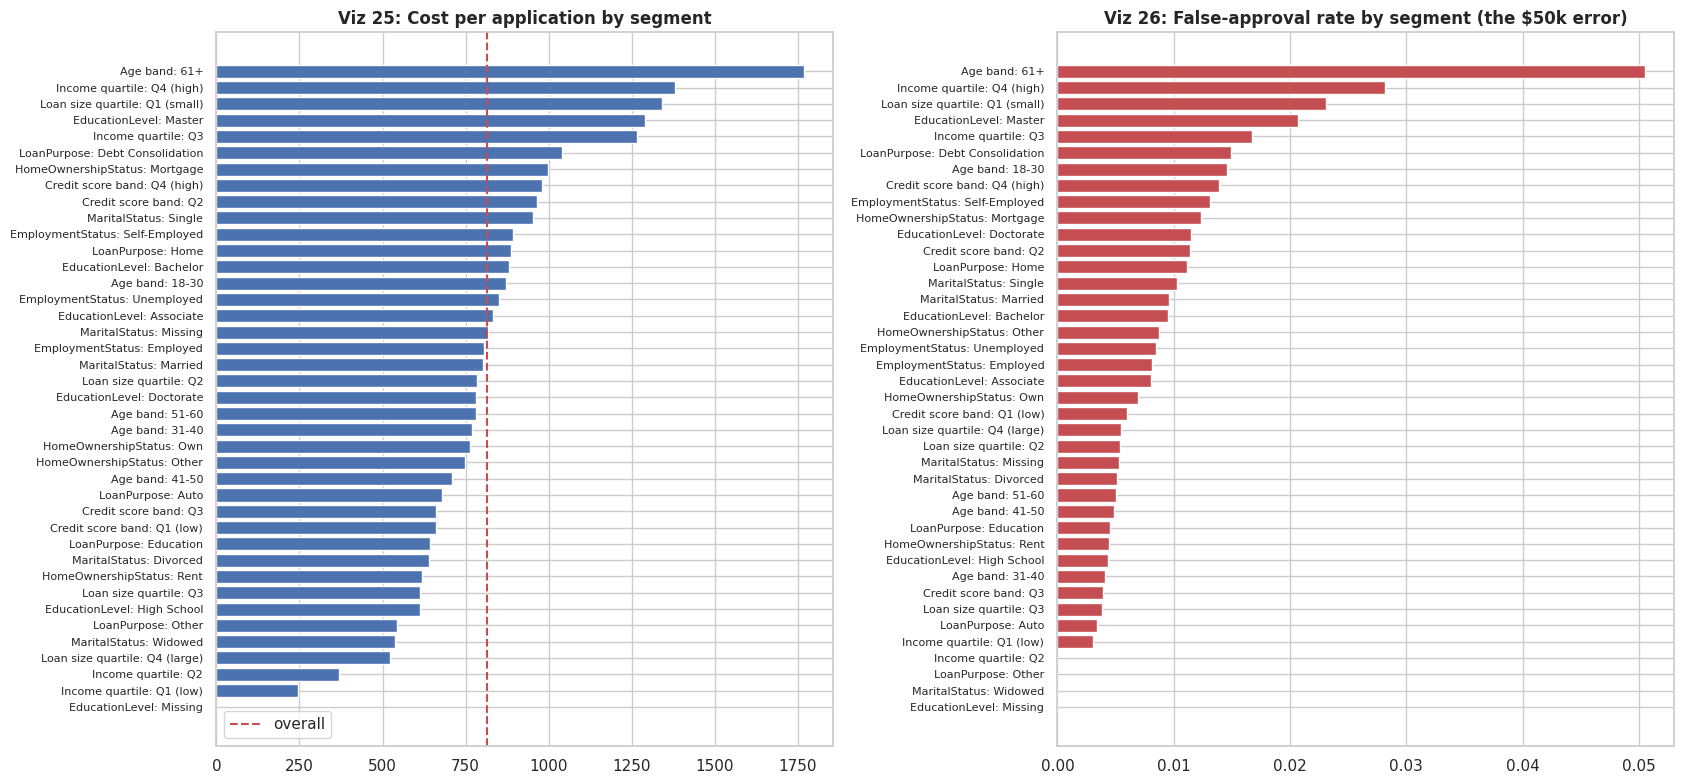

In [ ]:
# ---------------------------------------------------------------- Segment analysis
ev = X_test.copy(); ev["y"] = y_test.values; ev["p"] = p_test; ev["pred"] = pred_test
ev["Age band"] = pd.cut(ev["Age"], [17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
ev["Income quartile"] = pd.qcut(ev["MonthlyIncome"] * 12, 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
ev["Loan size quartile"] = pd.qcut(ev["LoanAmount"], 4, labels=["Q1 (small)", "Q2", "Q3", "Q4 (large)"])
ev["Credit score band"] = pd.qcut(ev["CreditScore"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
for c in ["EducationLevel", "MaritalStatus"]: ev[c] = ev[c].fillna("Missing")
seg_dims = ["Age band", "MaritalStatus", "EducationLevel", "EmploymentStatus", "HomeOwnershipStatus", "LoanPurpose",
            "Income quartile", "Loan size quartile", "Credit score band"]

def seg_table(dim):
    rows = []
    for g, s in ev.groupby(dim, observed=True):
        auc = roc_auc_score(s["y"], s["p"]) if s["y"].nunique() == 2 else np.nan
        neg = (s["y"] == 0).sum()
        rows.append({"dimension": dim, "segment": str(g), "n": len(s), "actual approval": s["y"].mean(), "predicted approval": s["pred"].mean(),
                     "AUC": auc, "false-approval rate": ((s["pred"] == 1) & (s["y"] == 0)).sum() / max(neg, 1),
                     "recall": recall_score(s["y"], s["pred"], zero_division=np.nan), "cost/app ($)": business_cost(s["y"], s["pred"]) / len(s)})
    t = pd.DataFrame(rows)
    t["DI ratio (pred)"] = t["predicted approval"] / t["predicted approval"].max()
    t["DI ratio (actual)"] = t["actual approval"] / t["actual approval"].max()
    return t
seg = pd.concat([seg_table(d) for d in seg_dims], ignore_index=True)
display(seg.set_index(["dimension", "segment"]).round(3))

flag = seg[(seg["DI ratio (pred)"] < 0.8) & (seg["n"] >= 30)]
print("\nSegments with predicted-approval DI ratio < 0.80:"); display(flag[["dimension", "segment", "n", "actual approval", "predicted approval", "DI ratio (pred)", "DI ratio (actual)"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(17, 8))
ss = seg.assign(label=seg["dimension"] + ": " + seg["segment"]).sort_values("cost/app ($)")
ax[0].barh(ss["label"], ss["cost/app ($)"], color=sns.color_palette("deep", len(seg_dims))[0]); ax[0].axvline(business_cost(y_test, pred_test) / len(y_test), color="r", ls="--", label="overall")
ax[0].set_title("Viz 25: Cost per application by segment"); ax[0].tick_params(axis="y", labelsize=8); ax[0].legend()
ss2 = seg.assign(label=seg["dimension"] + ": " + seg["segment"]).sort_values("false-approval rate")
ax[1].barh(ss2["label"], ss2["false-approval rate"], color="#c44e52"); ax[1].set_title("Viz 26: False-approval rate by segment (the $50k error)"); ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

,ROC-AUC,threshold,precision,recall,cost/app ($)
Full model,0.9888,0.9304,0.9647,0.7437,815.0
Without Age / Marital / Experience,0.9877,0.8163,0.9706,0.7259,786.5


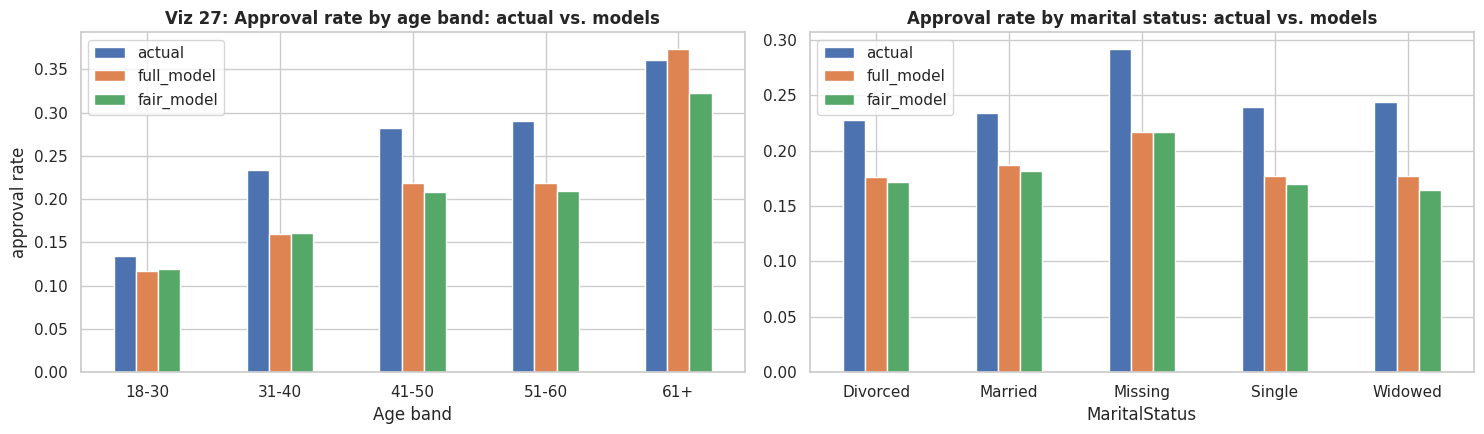

In [ ]:
# ---------------------------------------------------------------- Bias mitigation experiment: remove protected attributes and their proxies
PROTECTED = ["Age", "MaritalStatus", "Experience"]     # Age/marital status are protected in US lending (ECOA); Experience is ~0.98 correlated with Age
best_params_final = gs_lr.best_params_
fair_pipe = make_pipeline(LogisticRegression(max_iter=3000), exclude=PROTECTED).set_params(**best_params_final).fit(X_train, y_train)
p_fair = fair_pipe.predict_proba(X_test)[:, 1]

oof_f = cross_val_predict(clone(fair_pipe), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
cost_f = np.array([business_cost(y_train, (oof_f >= t).astype(int)) for t in thr_grid]); thr_f = float(thr_grid[cost_f.argmin()])
pred_f = (p_fair >= thr_f).astype(int)

cmp_fair = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, p_test), roc_auc_score(y_test, p_fair)],
    "threshold": [thr_opt, thr_f],
    "precision": [precision_score(y_test, pred_test), precision_score(y_test, pred_f)],
    "recall": [recall_score(y_test, pred_test), recall_score(y_test, pred_f)],
    "cost/app ($)": [business_cost(y_test, pred_test) / n_t, business_cost(y_test, pred_f) / n_t]},
    index=["Full model", "Without Age / Marital / Experience"])
display(cmp_fair.round(4))

ev["pred_fair"] = pred_f
age_cmp = ev.groupby("Age band", observed=True).agg(actual=("y", "mean"), full_model=("pred", "mean"), fair_model=("pred_fair", "mean"))
mar_cmp = ev.groupby("MaritalStatus").agg(actual=("y", "mean"), full_model=("pred", "mean"), fair_model=("pred_fair", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
age_cmp.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Viz 27: Approval rate by age band: actual vs. models"); ax[0].set_ylabel("approval rate")
mar_cmp.plot.bar(ax=ax[1], rot=0); ax[1].set_title("Approval rate by marital status: actual vs. models")
plt.tight_layout(); plt.show()

**Segment findings and fairness audit**
- **Accuracy is uniform:** AUC is 0.98-0.99 in essentially every segment, so the model does not "fail" on a particular population.
- **Most differences in predicted approval mirror differences in the data**, not model-created bias: income quartile (Q1 approvals 0.5% vs Q4 54.5%), loan size, credit score band and education all have large *actual* approval gaps. The "DI ratio (pred)" is close to or only modestly lower than the "DI ratio (actual)" almost everywhere.
- **Age** is the segment to watch. Predicted approval runs from 11.7% (18-30) to 37.4% (61+), a DI ratio of 0.31 against 0.37 in the data: the model reproduces and slightly widens an existing gap. The 61+ group (n = 155) also has the highest false-approval rate (5.1%) and twice the average cost per application, but with only 155 applicants this is a signal to monitor, not a conclusion.
- **Marital status** is not a concern: every group has a DI ratio ≥ 0.81 (the four-fifths rule), consistent with the EDA finding that it has no relationship with approval.
- **Education = Missing** is never approved (0 of 193 test cases, as in training). This needs a business decision (see recommendations).

**Mitigation experiment.** Removing the protected attributes (`Age`, `MaritalStatus`) and the near-duplicate proxy `Experience` (ρ = 0.985 with age) changes ROC-AUC from 0.9888 to 0.9877 and cost per application from $815 to $787 (not a meaningful difference at this sample size). There is no performance argument for using them, and a strong compliance argument against, so the **recommended production model excludes them**. Age effects can still enter through proxies such as credit-history length and income, so approval rates by age should keep being monitored.

### 5.3 Feature importance and interpretation
Two complementary views: **(1) standardised logistic-regression coefficients**, which give the direction and size of each driver and support adverse-action reasons; and **(2) permutation importance** on the held-out test set (the AUC lost when a *raw* column is shuffled), which is model-agnostic and measured on the original columns.

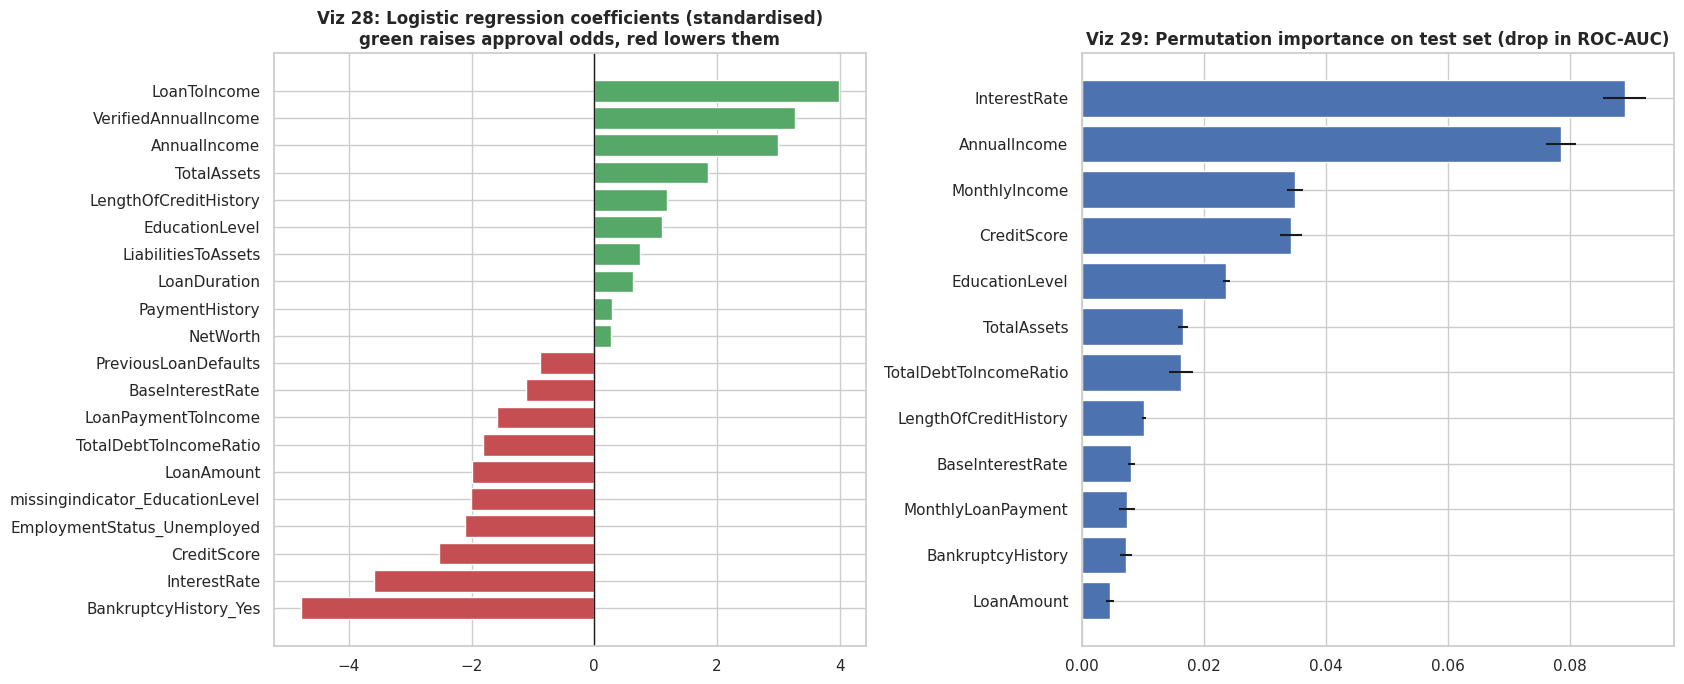

,AUC drop when shuffled
InterestRate,0.0889
AnnualIncome,0.0785
MonthlyIncome,0.0349
CreditScore,0.0343
EducationLevel,0.0237
TotalAssets,0.0166
TotalDebtToIncomeRatio,0.0162
LengthOfCreditHistory,0.0102
BaseInterestRate,0.0081
MonthlyLoanPayment,0.0074


,BankruptcyHistory_Yes,InterestRate,CreditScore,EmploymentStatus_Unemployed,missingindicator_EducationLevel,LoanAmount,TotalDebtToIncomeRatio,LoanPaymentToIncome,BaseInterestRate,PreviousLoanDefaults,NetWorth,PaymentHistory,LoanDuration,LiabilitiesToAssets,EducationLevel,LengthOfCreditHistory,TotalAssets,AnnualIncome,VerifiedAnnualIncome,LoanToIncome
coefficient,-4.785,-3.591,-2.536,-2.101,-2.006,-1.991,-1.813,-1.577,-1.117,-0.88,0.275,0.296,0.63,0.751,1.104,1.182,1.848,2.999,3.266,3.989


In [ ]:
# ---------------------------------------------------------------- Feature importance
names = final_pipe[:-1].get_feature_names_out()
coefs = pd.Series(final_pipe["model"].coef_[0], index=[n_.split("__", 1)[-1] for n_ in names]).sort_values()
top_c = pd.concat([coefs.head(10), coefs.tail(10)])

perm = permutation_importance(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
perm_sd = pd.Series(perm.importances_std, index=X_test.columns)[perm_s.index]

fig, ax = plt.subplots(1, 2, figsize=(17, 7))
ax[0].barh(top_c.index, top_c.values, color=np.where(top_c.values > 0, "#55a868", "#c44e52"))
ax[0].set_title("Viz 28: Logistic regression coefficients (standardised)\ngreen raises approval odds, red lowers them"); ax[0].axvline(0, color="k", lw=1)
top_p = perm_s.head(12)[::-1]
ax[1].barh(top_p.index, top_p.values, xerr=perm_sd[top_p.index], color="#4c72b0"); ax[1].set_title("Viz 29: Permutation importance on test set (drop in ROC-AUC)")
plt.tight_layout(); plt.show()
display(perm_s.head(10).round(4).to_frame("AUC drop when shuffled"))
display(top_c.round(3).to_frame("coefficient").T)

**Interpretation and business recommendations**
- **Permutation importance (most reliable view):** `InterestRate` (AUC drop 0.089), `AnnualIncome` (0.079), `MonthlyIncome`, `CreditScore`, `EducationLevel`, `TotalAssets` and `TotalDebtToIncomeRatio` lead. Income appears twice because income and monthly income are nearly the same signal, so their importance is shared.
- **Coefficients (direction):** a bankruptcy history (−4.8), a higher interest rate (−3.6), a lower credit score (−2.5), unemployment (−2.1), a missing education record (−2.0), a larger loan relative to income and a higher debt-to-income ratio (−1.8) lower approval odds; income, longer credit history and more assets raise them. All signs match credit-risk intuition. **Caution:** income, verified income and loan-to-income are strongly correlated, so their individual coefficients (e.g. the positive sign on `LoanToIncome`, offset by negative `LoanAmount`) should be read as a *group*, not one by one. For adverse-action reasons use grouped reason codes, not single coefficients.
- **Recommendations:** (1) price and screen on *affordability* (DTI, income) first, since it is the strongest and most defensible lever; (2) treat bankruptcy and prior default as near-hard rules; (3) investigate why missing education leads to denial, since if applicants are simply failing to complete a form field, the company is turning away business by process friction rather than risk; (4) **verify when `InterestRate` is set**: if it is assigned *after* the credit decision (risk-based pricing), it is a leakage feature and must be removed before deployment (see limitations).

### 5.4 Classification vs. regression: what we learned
We also tried the regression framing: predict `RiskScore` from the same pipeline (without the target and, of course, without using `RiskScore` as an input), then approve when the predicted score is below a cost-optimised cutoff.

| Approach | Quality of the model itself | Test cost per application |
|---|---|---|
| **Classification** (LR, cost-optimised threshold) | AUC 0.989 | **$815** |
| Regression → cutoff (HGB regressor, R² 0.91, MAE 1.5 points) | AUC 0.930 as a ranker | $1,356 (66% higher) |

The regressor is a good *score* predictor (CV R² 0.91 for boosting vs 0.81 for Ridge), but R² is the wrong objective for our problem: squared error is spread across the whole score range, while the business only cares about the region near the approve/deny boundary. In addition, `RiskScore` itself embeds the approval decision, which cannot be recovered from applicant features alone. Classification optimises the quantity we are paid on and gives a probability that loan officers can also read as a risk score, so it is the better primary framing. The regression score remains a useful *secondary* signal for pricing or for ordering a manual-review queue.

### 5.5 Limitations, potential biases and risks
1. **Proxy label.** `LoanApproved` is a historical decision, not a realised default. The model learns to *replicate past decisions* (including their biases) and the dollar figures hold only if those decisions are the right ground truth. Before go-live, retrain on actual repayment outcomes.
2. **Suspiciously high accuracy.** An AUC of 0.99 is far above what real credit data typically allows. It suggests the decisions in this dataset follow a largely deterministic rule on the recorded features. Expect lower performance on real applicants; do not promise the $21.9M figure externally.
3. **Possible timing leakage.** `InterestRate`, `BaseInterestRate` and `MonthlyLoanPayment` are the top-ranked drivers; if they are set *after* an approval decision they would not be available at application time. Confirm with the product team and, if needed, re-run without them (the notebook is structured so that removing them is a one-line change to the column lists).
4. **Selection bias / reject inference.** Real repayment data exists only for approved loans; the model is silent about how denied applicants would have performed, which may be where "overlooked creditworthy applicants" are hiding.
5. **Small error counts.** 26 false approvals on the test set means the dollar estimate is noisy; confidence intervals (e.g. bootstrap) and a larger out-of-time test set are needed.
6. **Fairness.** Segment gaps in approval by age and education mirror gaps in the training data and may encode historical bias. Mitigation here is limited to excluding protected attributes; formal tests (e.g. equal-opportunity, counterfactual checks) and legal review are required.
7. **Informative missingness.** `EducationLevel` missing ⇒ denied is a strong learned pattern whose cause is unknown; if it reflects a process failure, the model automates that failure.
8. **Calibration/threshold drift.** The threshold (0.93) depends on class weights and on the current approval mix and will need to be re-estimated when the applicant population or the cost figures ($50k / $8k) change.

## 6. Conclusion & Executive Summary
### Executive summary (for business stakeholders)

**The problem.** Manual loan reviews are slow and inconsistent. A bad approval costs us $50,000, a missed good loan $8,000, so errors are far from symmetric.

**What we built.** A transparent scoring model that estimates each applicant's likelihood of approval and converts it to a decision using a cut-off chosen to minimise dollar losses, not to maximise "accuracy". We tested it on 4,000 applications it had never seen.

**Results at a glance**

| Success criterion (set up-front) | Target | Result | Met? |
|---|---|---|---|
| Ranking quality (ROC-AUC) | ≥ 0.90 | **0.989** | ✅ |
| Precision of approvals | ≥ 90% (break-even 86.2%) | **96.5%** | ✅ |
| Cost vs best naive policy (deny-all) | ≥ 50% lower | **57% lower** ($815 vs $1,912 per application) | ✅ |
| Interpretable and auditable | Yes | Logistic regression + documented pipeline | ✅ |
| No large unexplained fairness gaps | Monitor | Gaps mirror the data; age needs monitoring; protected attributes removable at no cost | ⚠️ |

**Money.** About **$21.9M lower losses per 20,000 applications** than denying everyone (and $745M lower than approving everyone). The key risk is *false approvals*: only 26 in 4,000 test cases, but each costs $50k. The model approves roughly 3 in 4 of the genuinely creditworthy applicants, with 96.5% of its approvals being sound.

**What drives decisions.** Affordability (debt-to-income, income, loan-to-income), interest rate, credit score, bankruptcy and prior-default history, employment status and education record. These are intuitive and can be translated into customer-facing reasons.

### Recommendations for implementation
1. **Pilot in "shadow mode" for 2-3 months**: the model scores applications silently while officers decide as usual. Compare against actual repayment, not only against decisions, before any automation.
2. **Three-lane decisioning.** Auto-approve at P ≥ 0.93; auto-decline at very low scores; send the middle band to loan officers with the model's top reasons. This keeps humans where the model is unsure and where the $50k risk sits.
3. **Remove `Age`, `MaritalStatus` and `Experience`** from the production model (no meaningful accuracy cost) and run quarterly approval-rate and false-approval-rate audits by age, education and other segments.
4. **Resolve two data questions before go-live**: (a) is `InterestRate` known before the decision? (b) why does a missing `EducationLevel` always lead to denial? Fix the intake form if it is process friction.
5. **Evaluate the boosted challenger** (≈ $4.4M per 20,000 applications cheaper) with an explainability layer acceptable to Compliance.
6. **Monitor and recalibrate**: track score drift, approval mix and the threshold's cost curve monthly; re-tune if the $50k/$8k economics change.

### Potential improvements
- Replace the proxy label with **realised default/repayment outcomes**, and apply reject-inference methods.
- Use **probability calibration** (Platt/isotonic) so the theoretical 0.862 break-even applies directly.
- Add **bootstrap confidence intervals** on cost, and test on an **out-of-time** sample.
- Explore **interactions and monotonic gradient boosting** (monotone constraints keep boosted models regulator-friendly) and **SHAP** explanations.
- Add **cost-sensitive training** (sample weights of 50:8) and a **three-class output** (approve / review / decline) optimised for review capacity.
- Run formal **fairness testing** (equal opportunity, counterfactual fairness) with legal review.

*Prepared following the CRISP-DM framework: Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment recommendations.*